In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
import os
from scipy import signal
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore

import sys
sys.path.append('..')

## Fingerprinting + studiare consistenza tau tra individui

In [3]:
import sys
sys.path.append('..')

In [4]:
from my_module import *

In [5]:
def cluster_regions_EC(X,aggregate):

    ntimes,nregions = np.shape(X)
    nregions_aggregate = len(np.unique(aggregate))
    
    Y = np.zeros((nregions_aggregate,nregions_aggregate))
    
    for i in np.unique(aggregate):
        for j in np.unique(aggregate):
            clustered_regions = np.where(aggregate==i)[0]
            c = np.mean(X[clustered_regions,:],0)[np.newaxis,:]
            clustered_regions = np.where(aggregate==j)[0]
            Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
        

    return Y

In [6]:
sys.path.append('../pyMOU-master/pymou/')

In [7]:
from mou_model import *

In [8]:
#rcellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)
            #print('here')

100%|██████████| 1097/1097 [00:22<00:00, 49.83it/s]


In [7]:
from mou_model import *

In [26]:
data_ref=signal.filtfilt(b,a,data_1,axis = 0)
Y = data_ref
#cluster_regions(data_ref, aggregate)

m = MOU()
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,1)

m.fit_LO(Q0,Q1,lag = 1,prior =0.,tau=float(0.7), eta_C=0.005, max_iter = 100)
J_prior = m.J;


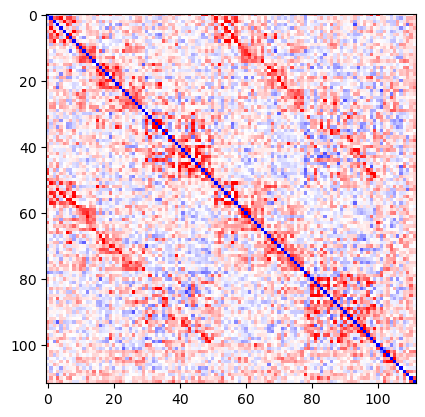

In [28]:
plt.imshow(J_prior, vmin=-.1, vmax=.1, cmap='bwr');

In [12]:
import scipy

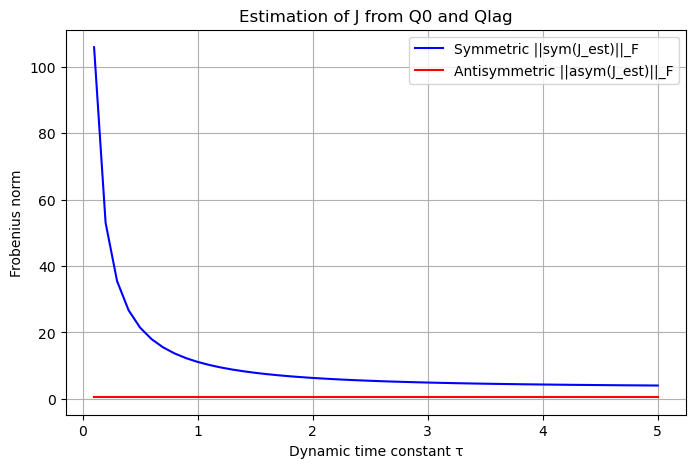

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import logm, solve_continuous_lyapunov

# Dimensione
#N = 5
np.random.seed(0)

# Connettività reale C
C = dediag(J_prior)
#np.random.randn(N, N)

# Rumore Σ
Sigma = m.Sigma

# Lag per la covarianza
t_lag = 1.0

# Range di tau dinamica
taus = np.linspace(0.1, 5.0, 50)

# Liste per le norme
norm_sym = []
norm_asym = []

for tau in taus:
    # Steady-state covariance Q0 via Lyapunov
    A = -np.eye(N)/tau + C
    Q0 = solve_continuous_lyapunov(A.T, -Sigma)
    
    # Lagged covariance
    Qlag = np.real(scipy.linalg.expm(A * t_lag) @ Q0)
    
    # Stima J
    J_est = (1/t_lag) * logm(Qlag @ np.linalg.inv(Q0))
    
    # Simmetrica e antisimmetrica
    sym_J = 0.5 * (J_est + J_est.T)
    asym_J = 0.5 * (J_est - J_est.T)
    
    norm_sym.append(np.linalg.norm(sym_J, 'fro'))
    norm_asym.append(np.linalg.norm(asym_J, 'fro'))

# Plot
plt.figure(figsize=(8,5))
plt.plot(taus, norm_sym, label='Symmetric ||sym(J_est)||_F', color='blue')
plt.plot(taus, norm_asym, label='Antisymmetric ||asym(J_est)||_F', color='red')
plt.xlabel('Dynamic time constant τ')
plt.ylabel('Frobenius norm')
plt.title('Estimation of J from Q0 and Qlag')
plt.legend()
plt.grid(True)
plt.show()


In [16]:
905-11, 911-11

(894, 900)

In [5]:
#cellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=200
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)

100%|██████████| 1097/1097 [00:33<00:00, 32.75it/s]


In [317]:
fc_1_74 = np.asarray(fc_1)
fc_2_74 = np.asarray(fc_2)


In [318]:
JS.shape

(1013, 74, 74)

In [18]:
fc_2=[]
l=0
nparcel=100 # IMPO 100 SE POI E USO 72 
#JS_2 =[]
pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))

if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
for sub in tqdm(sub_tot):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        #data_ref = data_1
        Y =cluster_regions(data_ref,aggregate)
        #m = MOU()
        Q0 = calc_Corr0(Y)
        Q1 = calc_Corrlag(Y,1)
        """
        m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=.7,eta_C =0.005,max_iter = 1000)
        J_prior =m.J;

        if np.sum(dediag(J_prior))==0:
        
            m = MOU()
            Q0 = calc_Corr0(Y)
            Q1 = calc_Corrlag(Y,1)
            m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.,eta_C =0.005,max_iter =1000)
            J_prior =m.J;
            print(np.sum(dediag(J_prior)))
            
        """
        #JS_2.append(J_prior)
    
        fc_2.append(Q0)

        #sub_tot.append(sub)
    else:
        l+=1


100%|██████████| 1013/1013 [00:15<00:00, 66.43it/s]


In [19]:
fc_1=[]
l=0
#JS = []
#sub_tot =[]
#JS = JS[:911]
#JS =JS.tolist()
nparcel=100 # IMPO 100 SE POI E USO 72 

if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
    
for sub in tqdm(sub_tot[:]):
    if os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        #data_ref = data_1
        Y = cluster_regions(data_ref,aggregate)
        #m = MOU()
        Q0 = calc_Corr0(Y)
        Q1 = calc_Corrlag(Y,1)
        """
        try:
            m.fit_LO(Q0,Q1,lag = 1,prior =0.,tau=.7, eta_C=0.005,max_iter = 1000)
            J_prior = m.J;
            if np.sum(dediag(J_prior))==0:
                m = MOU()
                Q0 = calc_Corr0(Y)
                Q1 = calc_Corrlag(Y,1)
                m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.,eta_C =0.005,max_iter = 1000)
                J_prior =m.J;
                print(np.sum(dediag(J_prior)))
        except:
            J_prior = np.zeros((Q0.shape[0],Q0.shape[0]))
            print('exception')
         
        if np.sum(dediag(J_prior))>269 or np.sum(dediag(J_prior))==0:
        
            m = MOU()
            Q0 = calc_Corr0(Y)
            Q1 = calc_Corrlag(Y,1)
            m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.1,eta_C =0.005,max_iter = 1000)
            J_prior =m.J;
            print('2nd try', np.sum(dediag(J_prior)))
        
        """
        #JS.append(J_prior)
        Q0 = calc_Corr0(Y)
        fc_1.append(Q0)
    else:
        l+=1


100%|██████████| 1013/1013 [00:17<00:00, 59.09it/s]


In [9]:
fc_1_74 = np.asarray(fc_1)
fc_2_74 = np.asarray(fc_2)


NameError: name 'fc_1' is not defined

In [8]:
fc_1_100 = np.asarray(fc_1)
fc_2_100 = np.asarray(fc_2)


NameError: name 'fc_1' is not defined

In [14]:
fc_1_200 = np.asarray(fc_1)
fc_2_200 = np.asarray(fc_2)

In [328]:
fc_1_200.shape

(1013, 212, 212)

In [329]:
JS = np.asarray(JS)
JS_2 = np.asarray(JS_2)
JS.shape, JS_2.shape,JS_200_1.shape, JS_100_1.shape

((1013, 74, 74), (1013, 74, 74), (1024, 212, 212), (1013, 112, 112))

In [14]:
ls ../../numpy\ files

 dcm_sorted.npy           EC_ms_200.npy         ecs_dcm_ms.npy
 EC_hc_200.npy            EC_ms_ihmask.npy     'ec + sub.npy'
 EC_hc_ihmask.npy         EC_ms_mask_minC.npy   matrici_dcm_HCP_corr.npy
 EC_hc_mask_minC.npy      ec_ms_new_100.npy     matrici_MOU_corr.npy
 EC_hc_not_mask.npy       ec_ms_new_62.npy      matrici_MOU_HCP_corr.npy
 EC_hc.npy                ec_ms_new_72.npy      matrici_MOU.npy
 EC_matrix_HCP1_100.npy   ec_ms_new_cov.npy     mean_EC_200.npy
 EC_matrix_HCP1_200.npy   ec_ms_new.npy         mou_sorted.npy
 EC_matrix_HCP2_100.npy   EC_ms_not_mask.npy
 EC_matrix_HCP2_200.npy   EC_ms.npy


In [15]:
os.chdir('../..')
JS_100_1 = np.load("numpy files/EC_matrix_HCP1_100.npy")
JS_200_1 = np.load("numpy files/EC_matrix_HCP1_200.npy")


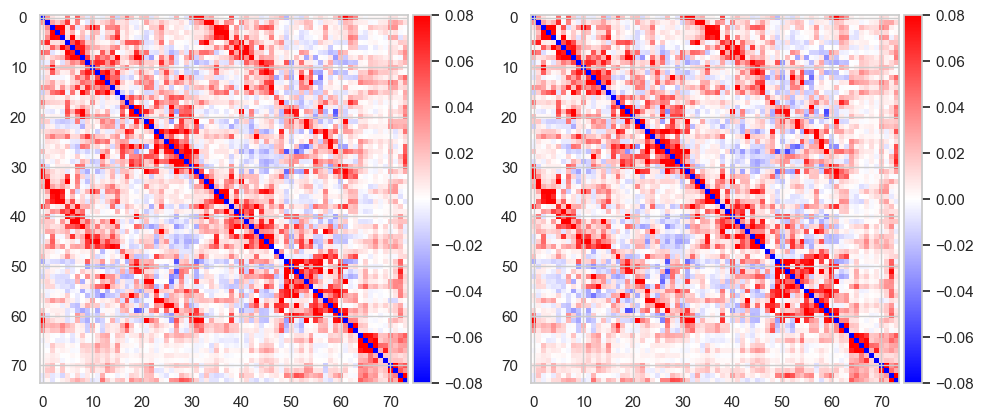

In [129]:
two_plots(np.mean(JS,0), np.mean(JS_2,0), 0.08,0.08, 1,"","");

In [130]:
len(sub_tot),len(sub_tot_)


(1013, 1024)

In [433]:
np.mean(c1), np.mean(c2)

(np.float64(0.9662494649143201), np.float64(0.9647149838513821))

In [29]:
l = []
for i in range(JS_new.shape[0]):
    #print(i)
    if np.max(JS_new[i])<0.02:
        l.append(i)
        #print(i,np.sum(dediag(JS_new[i])))
        
indici = (np.unique(l))
print(indici.shape)

#print(np.max(JS[379])<0.02)

l = []
for i in range(JS_new.shape[0]):
    if np.max(JS_new[i])<0.02:
        l.append(i)
        #print(i,np.sum(dediag(JS_new_2[i])))
indici2 = (np.unique(l))
indici2.shape
#indici2,indici

NameError: name 'JS_new' is not defined

In [222]:
indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)

(170, 170, 170)

In [217]:
JS_200

(1000, 112, 112)

In [223]:
JS_new = np.delete(JS_new,indici_,0)
#JS_new_2 = np.delete(JS_new_2,indici_,0)

In [219]:
set2=(np.where(np.array(list(map(np.sum, np.array(list(map(dediag, JS_200_1))))))==0)[0])
set1=(np.where(np.array(list(map(np.sum, np.array(list(map(dediag, JS_2))))))==0)[0])
indici = np.asarray(list(set(set1) | set(set2)))
indici

array([864, 609,   2, 706, 897,   5, 198, 202, 911, 154, 763, 444,  30])

In [61]:
JS_200_1.shape

(1024, 212, 212)

In [60]:
np.max(JS_new[800])<0.02, JS_200_1.shape

NameError: name 'JS_new' is not defined

In [87]:
JS_neww = np.delete(JS_new,indici_,0)
JS_neww_2 = np.delete(JS_new_2,indici_,0)

((1024, 212, 212), (959, 212, 212), array([379, 544, 641, 698, 799, 832, 846]))

### Fingerprinting

In [13]:
fc_1 = np.asarray(fc_1)
fc_2 = np.asarray(fc_2)
print(fc_1.shape, fc_2.shape)

(1013, 212, 212) (1013, 212, 212)


In [19]:
indi = np.random.choice(np.arange(0,1013,1),1013, replace =False)
index = np.triu_indices(fc_1[0].shape[0],1)
X1 = np.asarray([i[index] for i in fc_1[indi]])
X2 =  np.asarray([i[index] for i in fc_2[indi]])
C = np.corrcoef(np.vstack([X1,X2]))[:X1.shape[0], X1.shape[0]:]
C = np.asarray(C)


c=[]
for i in range(len(C)):
    mask = (np.isnan(C[i]))
    C[i][mask] = 0
    if np.argmax(C[i]) ==i:
        c.append(1)
    else:
        c.append(0)
print('Pearson Cor: ',np.mean(c))

Pearson Cor:  0.6762092793682132


In [34]:
#C_vs_size = C_vs_size*n_real
#size = np.asarray(size)
#C_vs_size = C_vs_size/(n_real/size*50)

In [60]:
cifti100.get_fdata()

memmap([[39., 19., 13., ..., 83., 83., 83.]])

## Coarse Graining Figure

In [596]:
#(set(mapping.values()))

In [51]:
"""
import numpy as np
import nibabel as nib

# --- Load ---
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_17Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_17Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# --- 1. Vertici validi: quelli che hanno un'etichetta in entrambi i parcellamenti ---
valid = (schaefer100 > 0) & (schaefer200 > 0)

# --- 2. Mappa 200 → 100 usando solo i vertici validi ---
mapping_200_to_100 = {}

for parcel200 in np.unique(schaefer200[valid]):
    idx = np.where((schaefer200 == parcel200) & valid)[0]
    corresponding100 = schaefer100[idx]

    # parcel del 100 più frequente (modal value)
    parcel100 = np.bincount(corresponding100).argmax()

    mapping_200_to_100[parcel200] = parcel100

# --- mapping_200_to_100 ora è un dict {parcel200: parcel100}
#print(mapping_200_to_100)
"""

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [58]:
len(np.unique(corresponding100)),len(corresponding100)

(3, 215)

In [ ]:
np.amax(

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


183
(200,)


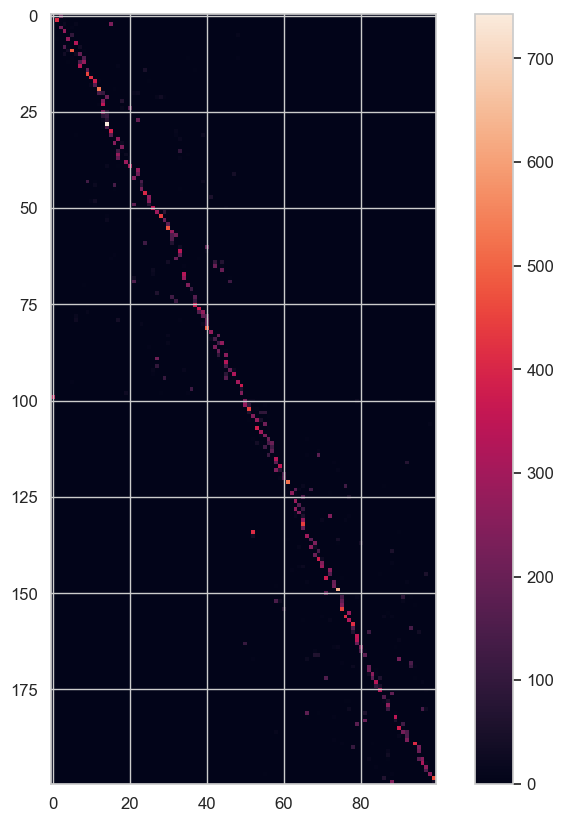

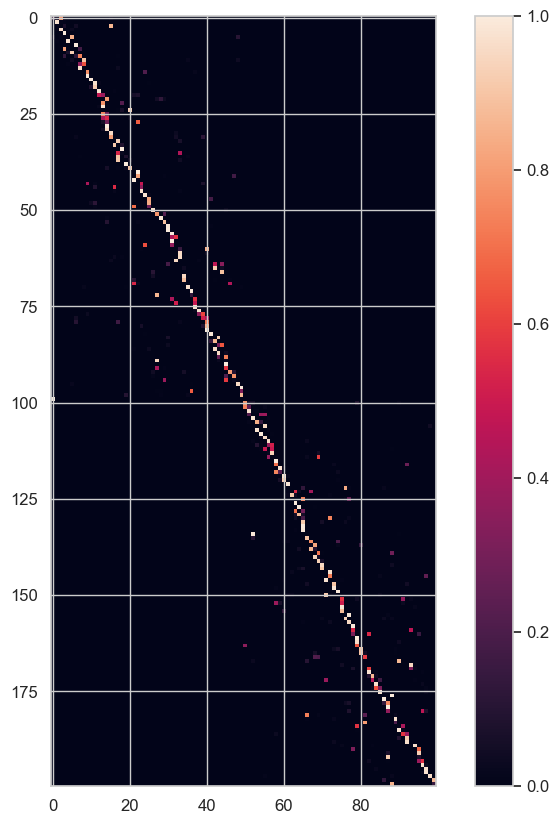

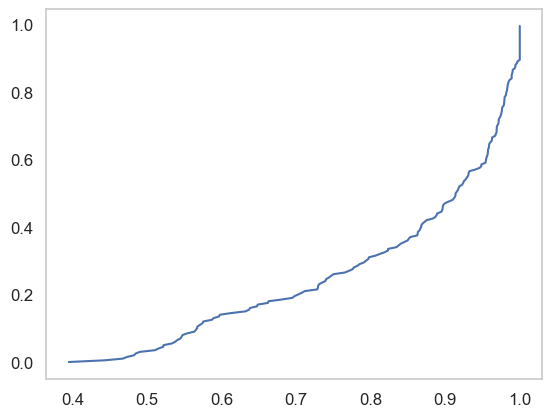

In [383]:
import nibabel as nib
import numpy as np

# === 1. CARICAMENTO DEI CIFTI ===
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_7Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# === 2. COSTRUZIONE MAPPATURA 200 → 100 ===
labels200 = np.unique(schaefer200)
#print(len(labels200))
labels200 = labels200[labels200 > 0]

confusion_matrix = np.zeros((200,100))

mapping = {}
for i,l200 in enumerate(labels200):
    mask = (schaefer200 == l200)
    overlapping = schaefer100[mask]
    overlapping = overlapping[overlapping > 0]
    if overlapping.size > 0:
        unique, bincounts = np.unique(overlapping,return_counts=True)
        mapping[l200] = unique[np.argmax(bincounts)]
        
    confusion_matrix[i,unique-1] = bincounts 



confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=1)[:,np.newaxis]

print(len(np.where(confusion_matrix1>0.55)[0]))


pmax = np.sort(confusion_matrix1,axis=1)[:,-1]

imax = np.argsort(pmax)

#print(np.sort(confusion_matrix1[imax,:],axis=1) [:10,-10:])
print(pmax.shape)

plt.figure(figsize=(10,10))
plt.imshow(confusion_matrix)
plt.colorbar()


plt.figure(figsize=(10,10))
plt.imshow(confusion_matrix1)
plt.colorbar()

plt.figure()

plt.plot(np.sort(pmax),np.arange(200)/200.)
plt.grid()

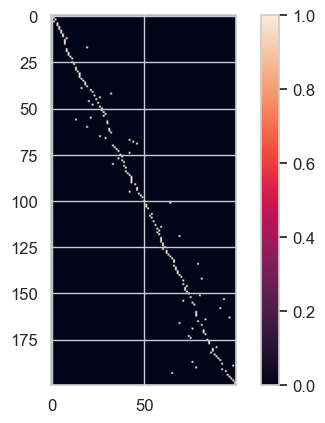

In [276]:
plt.imshow((confusion_matrix1>0.55))
plt.colorbar()

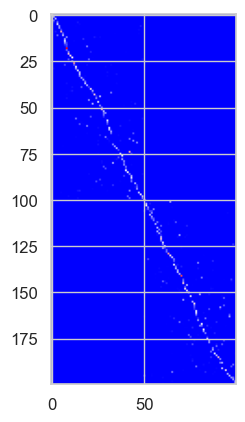

In [277]:
plt.imshow(confusion_matrix, cmap='bwr');

In [283]:
#np.sum(confusion_matrix,0)

In [354]:
np.where(confusion_matrix1>0.55)[0]


array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  17,  18,  19,  20,  21,  22,  23,  25,  26,  28,
        29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,
        42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,
        55,  56,  57,  58,  60,  61,  62,  63,  65,  66,  67,  68,  69,
        70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,
        84,  85,  86,  87,  88,  89,  90,  91,  93,  94,  95,  96,  97,
        98, 100, 101, 102, 103, 104, 107, 108, 109, 111, 113, 114, 115,
       116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128,
       129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141,
       142, 143, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 158, 160, 161, 162, 163, 164, 165, 166, 167, 169, 170, 171,
       172, 173, 174, 175, 176, 177, 179, 180, 181, 182, 183, 184, 185,
       186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 19

183
105
137
183


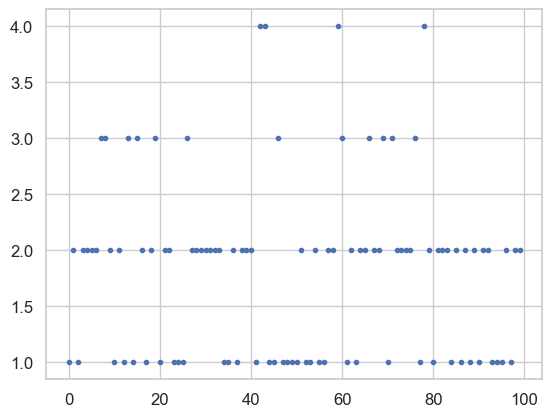

In [352]:
confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=1)[:, np.newaxis]

cc = np.sum(confusion_matrix1>0.55,axis=0)

plt.plot(cc,'.')
print(np.sum(cc))

print(len(np.where(confusion_matrix1>0.9)[0]))
print(len(np.where(confusion_matrix1>0.8)[0]))
print(len(np.where(confusion_matrix1>0.55)[0]))


pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


Mapping filtrato ottenuto con 160 parcelle valide.


(100, 100)

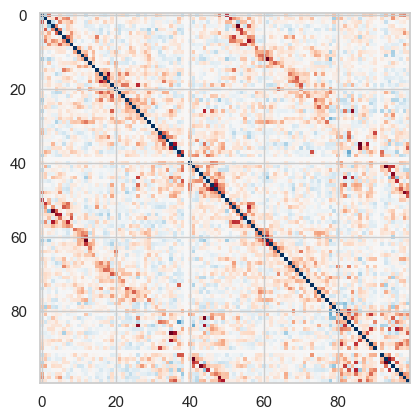

In [394]:
import nibabel as nib
import numpy as np
soglia=0.7
# === 1. CARICAMENTO CIFTI ===
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_7Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# === 2. CONFUSION MATRIX 200 → 100 ===
labels200 = np.unique(schaefer200)
labels200 = labels200[labels200 > 0]

confusion_matrix = np.zeros((len(labels200), 100))
mapping = {}

for i, l200 in enumerate(labels200):
    mask = (schaefer200 == l200)
    overlapping = schaefer100[mask]
    overlapping = overlapping[overlapping > 0]

    if overlapping.size > 0:
        unique, bincounts = np.unique(overlapping, return_counts=True)
        confusion_matrix[i, unique - 1] = bincounts

# Normalizzazione
confusion_matrix1 = confusion_matrix / np.sum(confusion_matrix, axis=1)[:, np.newaxis]

# === 3. SELEZIONE PARCELS VALIDI (>0.55) ===
valid_idx = np.where(confusion_matrix1 > soglia)[0]
valid_labels200 = labels200[valid_idx]

# === 4. COSTRUZIONE MAPPING FILTRATO ===
mapping_filtered = {}
for idx in valid_idx:
    l200 = labels200[idx]
    row = confusion_matrix1[idx]
    l100 = np.argmax(row) + 1   # 0-based → 1-based
    mapping_filtered[l200] = l100

print("Mapping filtrato ottenuto con", len(mapping_filtered), "parcelle valide.")

def downsample_matrix_200_to_100(matrix200, mapping200to100, agg='mean'):
    """
    Restituisce:
    - matrix100: matrice sotto-campionata 100x100
    - matrix200_filtered: matrice 200x200 ristretta solo alle parcelle valide
    
    matrix200: matrice originale 200x200
    mapping200to100: dict {parcel200 -> parcel100}
    agg: 'mean' (default) o 'sum'
    """

    # === 1. Estraggo i parcels 200 validi ===
    valid_parcels200 = np.array(list(mapping200to100.keys()))
    valid_parcels200.sort()

    # converto in indici 0-based per la matrice 200
    valid_idx = valid_parcels200 - 1

    # === 2. Creo la matrice 200 filtrata ===
    matrix200_filtered = matrix200[np.ix_(valid_idx, valid_idx)]

    # === 3. Costruisco la matrice 100 sotto-campionata ===
    matrix100 = np.zeros((100, 100))
    accum = {}
    counts = {}

    for p200_i in mapping200to100:
        for p200_j in mapping200to100:
            p100_i = mapping200to100[p200_i] - 1
            p100_j = mapping200to100[p200_j] - 1

            key = (p100_i, p100_j)

            if key not in accum:
                accum[key] = 0.0
                counts[key] = 0

            accum[key] += matrix200[p200_i - 1, p200_j - 1]
            counts[key] += 1

    for (i, j), val in accum.items():
        matrix100[i, j] = val / counts[(i, j)] if agg == 'mean' else val

    return matrix100, matrix200_filtered


# === 6. ESEMPIO DI USO ===
matrix200 = JS_200_1[0,:200,:200]
matrix100 = downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')[0]
plt.imshow(matrix100, vmin=-.1, vmax=.1, cmap='RdBu_r')
matrix100.shape

56


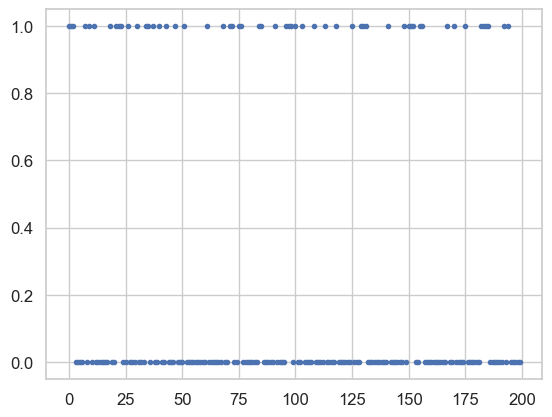

In [310]:
confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=0)
#[:,np.newaxis]
#confusion_matrix1.shape
cc = np.sum(confusion_matrix1>0.5,axis=1)

plt.plot(cc,'.')
print(np.sum(cc>0))

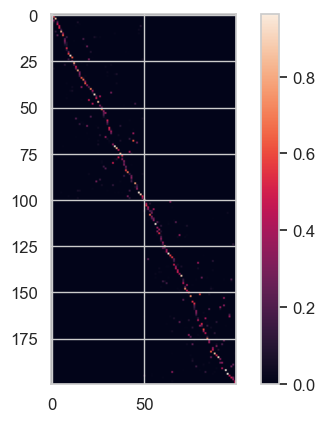

In [347]:
confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=0)

plt.imshow(confusion_matrix1)
plt.colorbar()

37


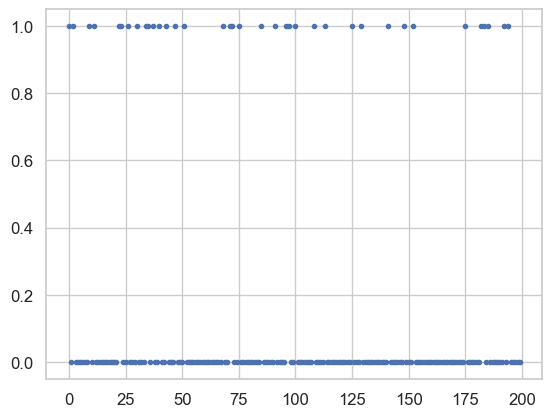

In [345]:
confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=0)
#[:,np.newaxis]
#[:,np.newaxis]
#confusion_matrix1.shape
cc = np.sum(confusion_matrix1>0.6,axis=1)

plt.plot(cc,'.')
print(np.sum(cc>0))

In [223]:

parcel=np.where(np.sum(confusion_matrix1>0.95,axis=0))[0]+1
parcel, parcel.shape, n100

(array([  1,   2,   3,   4,   5,   8,   9,  10,  11,  12,  13,  14,  15,
         18,  20,  21,  22,  24,  26,  28,  29,  30,  31,  33,  35,  36,
         37,  39,  40,  41,  42,  43,  44,  46,  47,  48,  49,  51,  52,
         53,  54,  55,  58,  59,  60,  61,  62,  63,  64,  65,  69,  70,
         71,  72,  74,  76,  77,  78,  79,  82,  83,  85,  86,  87,  88,
         89,  90,  93,  95,  96,  99, 100]),
 (72,),
 85)

In [392]:
n100

100

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


Mapping 200 → 100 completato. Numero ROI100: 100
Matrice 100×100 creata: (100, 100)
(200, 200)
(100, 100)


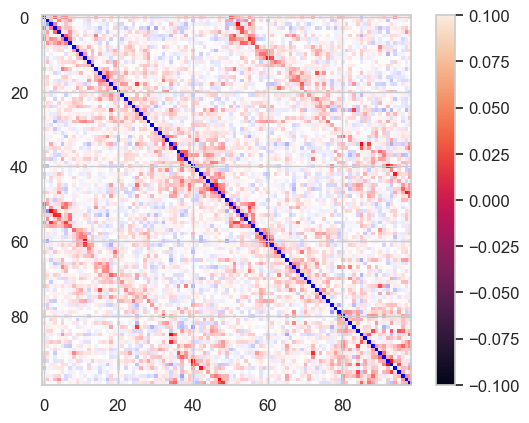

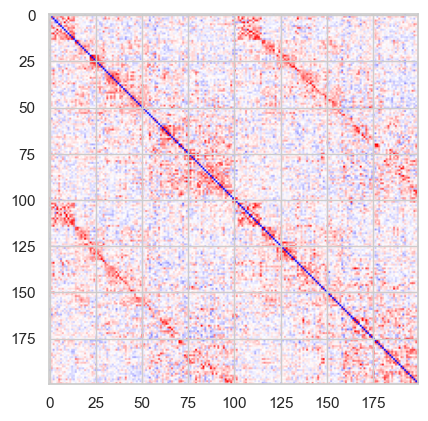

In [400]:

import nibabel as nib
import numpy as np

# === 1. CARICAMENTO DEI CIFTI ===
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_7Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# === 2. COSTRUZIONE MAPPATURA 200 → 100 ===
labels200 = np.unique(schaefer200)
#print(len(labels200))
labels200 = labels200[labels200 > 0]

confusion_matrix = np.zeros((200,100))

mapping = {}

#parcel=np.where(np.sum(confusion_matrix1>0.9,axis=0))[0]

for i,l200 in enumerate(labels200):
    mask = (schaefer200 == l200)
    overlapping = schaefer100[mask]
    overlapping = overlapping[overlapping > 0]
    if overlapping.size > 0:
        unique = np.unique(overlapping)
        bincount = np.bincount(overlapping)
        mapping[l200] = np.argmax(bincount)

plt.imshow(confusion_matrix)
plt.colorbar()





print("Mapping 200 → 100 completato. Numero ROI100:", len(set(mapping.values())))

# === 3. CONVERSIONE MATRICE 200×200 → 100×100 ===
# Carica o definisci la tua matrice di connettività 200x200 qui:
# Esempio placeholder (rimuovi e sostituisci con il tuo file!)
# C200 = np.load("connectome_200.npy")

# Se non hai ancora la matrice, crea un placeholder per evitare errori:
# (commenta questa linea quando hai i tuoi dati)
C200 = np.load('numpy files/EC_matrix_HCP1_200.npy')[0][:200,:200]
#np.random.rand(200, 200)

roi100 = sorted(set(mapping.values()))
n100 = len(roi100)
C100 = np.zeros((n100,n100))

# lista delle ROI200 associate a ciascuna ROI100
roi200_by_100 = {l100: [] for l100 in roi100[:]}
for l200, l100 in mapping.items():
    #if l100 != 0:
    roi200_by_100[l100].append(l200)
#print(roi200_by_100)
# converti in indici (0-index)
roi200_by_100_idx = {l100: [r-1 for r in roi200_by_100[l100]] for l100 in roi200_by_100}
#print(roi200_by_100_idx)
def mapping_orig(C200):

    n100 = len(roi100)
    C100 = np.zeros((n100, n100))
    for i, l100_i in enumerate(roi100[:]):
        
        #print(l100_i)
        idx_i = roi200_by_100_idx[l100_i]
        #print(idx_i)
        for j, l100_j in enumerate(roi100[:]):
            idx_j = roi200_by_100_idx[l100_j]
            block = C200[np.ix_(idx_i, idx_j)]
            C100[i, j] = block.mean()
    return C100

print("Matrice 100×100 creata:", C100.shape)

import seaborn as sns    
sns.set(style="whitegrid")

plt.imshow(mapping_100_200(C200), cmap='bwr',vmin=-.1, vmax=.1);
plt.figure()

plt.imshow(C200,vmin=-.1, vmax=.1,cmap='bwr',)
print(C200.shape)
print(mapping_orig(C200).shape)


In [393]:
roi100 = sorted(set(mapping.values()))
len(roi100)

100

In [198]:
#JS_100_1.shape
JS_200_1 = np.load('numpy files/EC_matrix_HCP1_200.npy')
JS_100_1.shape
#JS_100_1.shape
JS_100_1 = np.load('numpy files/EC_matrix_HCP1_100.npy')
JS_100_1.shape

(1013, 112, 112)

(72, 72)
(72, 72) (72, 72)


[np.float64(0.29652600608452734)]

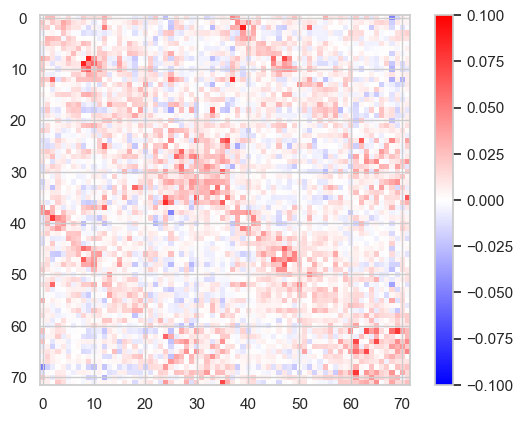

In [226]:
cors=[]
parc = np.asarray(roi100[1:])
j=0
y= (mapping_100_200(dediag(JS_200_1[j][:200,:200])))
print(y.shape)
x = dediag(JS_100_1[i][parc][:,parc])
print(x.shape, y.shape)
cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
#plt.hist(cors, bins = 50);
plt.imshow(y, cmap='bwr', vmin=-.1,vmax=.1)
plt.colorbar()
cors

In [367]:
JS_100_2.shape, JS_200_1.shape

((1013, 112, 112), (1024, 212, 212))

In [388]:
"""
import numpy as np
from nilearn.datasets import fetch_atlas_schaefer_2018

# --- 1. scarica atlas 200 e 100 ---
atlas200 = fetch_atlas_schaefer_2018(n_rois=200, yeo_networks=17, resolution_mm=1, verbose=1)
atlas100 = fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=17, resolution_mm=1, verbose=1)

labels200 = atlas200['labels']
labels100 = atlas100['labels']

# --- 2. costruisci dizionario roi_id -> network ---
net200 = { i+1: labels200[i].decode('utf-8').split('_')[1] for i in range(len(labels200)) }
net100 = { i+1: labels100[i].decode('utf-8').split('_')[1] for i in range(len(labels100)) }

# --- 3. mapping iniziale + network-constrained ---
raw_map = {p: (p+1)//2 for p in range(1, len(labels200)+1)}

mapping = {}
for p200, p100 in raw_map.items():
    if net200[p200] == net100.get(p100, None):
        mapping[p200] = p100
    else:
        candidates = [k for k,v in net100.items() if v == net200[p200]]
        mapping[p200] = min(candidates) if candidates else p100

# --- 4. esempio: aggrega matrice 200x200 in 100x100 ---
C200 = fc_1_200[0]

unique200 = list(mapping.keys())
unique100 = sorted(set(mapping.values()))
n100 = len(unique100)

def mapping_try_new(C200):
    
    C100 = np.zeros((n100, n100))
    counts = np.zeros((n100, n100))
    
    for p200_i in unique200:
        for p200_j in unique200:
            p100_i = mapping[p200_i]
            p100_j = mapping[p200_j]
            C100[p100_i-1, p100_j-1] += C200[p200_i-1, p200_j-1]
            counts[p100_i-1, p100_j-1] += 1
    
    C100 = np.divide(C100, counts, out=np.zeros_like(C100), where=counts!=0)
    #print("C100 shape:", C100.shape)
    return C100
plt.imshow(C100, cmap ='RdBu_r');
""";

In [ ]:
"""
import numpy as np
import nibabel as nib

# === LOAD CIFTI LABELS ===
path200 = "/home/allegra/atlases/Schaefer2018_200Parcels_17Networks_order.dlabel.nii"
path100 = "/home/allegra/atlases/Schaefer2018_100Parcels_17Networks_order.dlabel.nii"

s200_img = nib.load(path200)
s100_img = nib.load(path100)

labels200 = s200_img.get_fdata().astype(int).ravel()
labels100 = s100_img.get_fdata().astype(int).ravel()

# === MAPPING 200→100 ===
# Metodo 3: parcel100 = ceil(parcel200 / 2)
mapping = {p200: (p200 + 1) // 2 for p200 in np.unique(labels200)}
print(len(np.unique(labels200)),max(np.unique(labels100)))
# === LOAD CONNECTIVITY MATRIX 200×200 ===
# (metti la tua matrice)
C200 = np.random.rand(200,200)  # <--- sostituisci con la tua matrice 200×200

# === INIT 100×100 ===
def mapping_try(C200):
    
    C100 = np.zeros((100,100))
    counts = np.zeros((100,100))

    # === AGGREGAZIONE ===
    for p200_i in range(1,201):
        for p200_j in range(1,201):
            p100_i = mapping[p200_i]
            p100_j = mapping[p200_j]
            
            C100[p100_i-1, p100_j-1] += C200[p200_i-1, p200_j-1]
            counts[p100_i-1, p100_j-1] += 1
    
    # === MEDIA (evita divisione per zero) ===
    C100 = np.divide(C100, counts, out=np.zeros_like(C100), where=counts!=0)
    
    return C100
"""


In [533]:
plt.rcParams['font.size'] = 18

In [253]:
mapping_100_200(JS_200_1[subject,:200,:200]).shape

(72, 72)

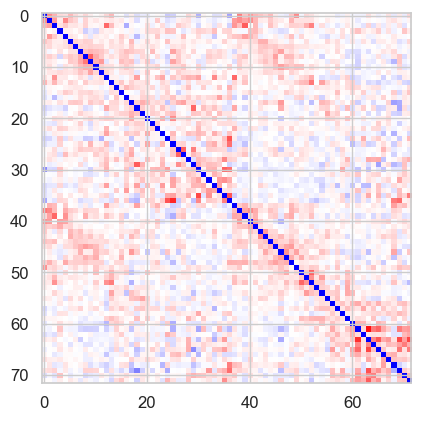

In [252]:
plt.imshow(mapping_100_200(JS_200_1[subject,:200,:200]), vmin=-.1, vmax =.1, cmap='bwr')

In [403]:
import matplotlib.pyplot as plt

cmap = plt.get_cmap("RdBu", 11)  # campiona 11 colori
colors_11 = cmap(range(11))


In [410]:
plt.style.use('default')

/tmp/ipykernel_54028/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


(62, 62) (62, 62)
1.0 1.0
(62, 62) (62, 62)
0.6461735422588656 0.97
(62, 62) (62, 62)
0.2711095179817669 0.87


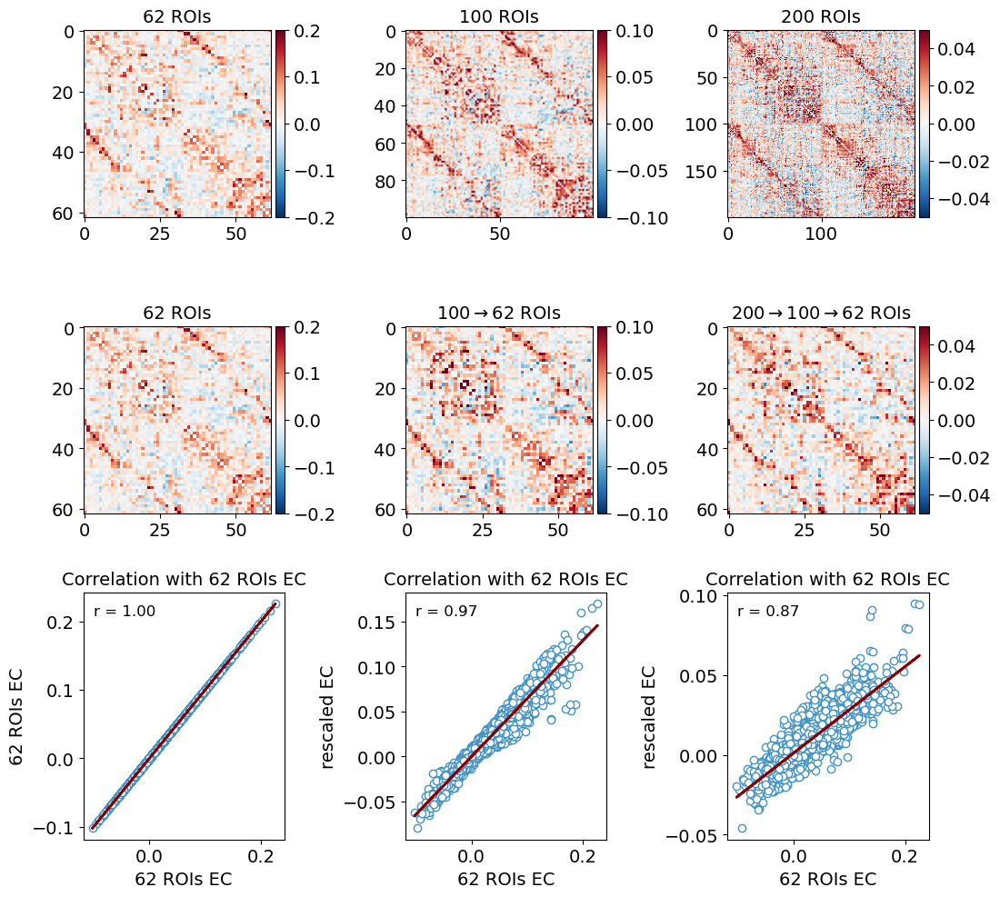

In [413]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(3, 3, figsize=(12,12), )
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 12

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14



# Primo pannello
v = [0.2,0.1,0.05, 0.2,0.1,0.05]

#downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')

js =[]
subject =80
js.append(dediag(JS[subject,:62,:62]))
js.append(dediag(JS_100_1[subject,:100,:100]))
js.append(dediag(JS_200_1[h][subject,:200,:200]))# np.mean(JS[:,:62,:62],0))
len(js)
js.append(js[0])
js.append(cluster_regions_EC(js[1], aggregate[:100]))
matrix200 = js[2]
js.append(cluster_regions_EC(mapping_orig(matrix200), aggregate[:100]))
    #downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')[0])
len(js)

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['62 ROIs', '100 ROIs', '200 ROIs', '62 ROIs', r'$100 \rightarrow 62$ ROIs', r'$200 \rightarrow 100 \rightarrow 62 $ ROIs', 
         'Correlation with 62 ROIs EC','Correlation with 62 ROIs EC', 'Correlation with 62 ROIs EC']
for i,ax in enumerate(axes.reshape(-1)[:6]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}")



from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore


#print(i)

# Dati


for i,ax in enumerate(axes.reshape(-1)[6:]):

    x = (dediag(js[0]))
    #if i ==2:
    #    x = js[1]
        #dediag(downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')[1])
    y = (dediag(js[i+3]))
    print(x.shape, y.shape)
    
    im= ax.scatter(x,y,c = 'white',edgecolor = colors_11[8]
                  )#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
    res = linregress(x.flatten(), y.flatten())
    slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue

    y_line = slope * x.flatten() + intercept
    ax.plot(x.flatten(), y_line, linewidth=2, color ='darkred')
    print(slope, r)
    from scipy import stats
    #res = stats.spearmanr(x.flatten(), y.flatten())
    # Titolo completo
    #print('sp', res)
    ax.set_title(f"{titles[i+6]}")
    ax.set_xlabel('62 ROIs EC')
    ax.set_ylabel('62 ROIs EC') if i == 0 else ax.set_ylabel('rescaled EC') 
    
    # --- Testo dentro la figura ---
    text_str = f"r = {r:.2f}"
    ax.text(
        0.05, 0.95,              # posizione (fractions dell'asse)
        text_str,
        transform=ax.transAxes,  # usa coordinate normalizzate
        verticalalignment='top',
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

    
#plt.tight_layout()  
plt.subplots_adjust(wspace=0.6, hspace=0.2)
plt.savefig('Figures/Coarse graining_singles.jpg', bbox_inches ='tight', dpi = 300)

In [381]:
len(JS_200_1[h])

1013

In [377]:
h = []
for _,i in enumerate(sub_tot_):
    if i in sub_tot:
        h.append(_)


len(h), h[:10]

(1013, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [379]:
sub_tot= np.asarray(sub_tot)
sub_tot_= np.asarray(sub_tot_)
np.array_equal(sub_tot, sub_tot_[h])

True

In [418]:
ls 'numpy files'

 dcm_sorted.npy                     EC_ms_mask_minC.npy
 EC_dcm_HCP1_74.npy                 ec_ms_new_100.npy
 EC_hc_200.npy                      ec_ms_new_62.npy
 EC_hc_ihmask.npy                   ec_ms_new_72.npy
 EC_hc_mask_minC.npy                ec_ms_new_cov.npy
 EC_hc_not_mask.npy                 ec_ms_new.npy
 EC_hc.npy                          EC_ms_not_mask.npy
 EC_matrix_HCP1_100.npy             EC_ms.npy
 EC_matrix_HCP1_200_converged.npy   ecs_dcm_ms.npy
 EC_matrix_HCP1_200.npy            'ec + sub.npy'
 EC_matrix_HCP1_74.npy              matrici_dcm_HCP_corr.npy
 EC_matrix_HCP2_100.npy             matrici_MOU_corr.npy
 EC_matrix_HCP2_200_converged.npy   matrici_MOU_HCP_corr.npy
 EC_matrix_HCP2_200.npy             matrici_MOU.npy
 EC_matrix_HCP2_74.npy              mean_EC_200.npy
 EC_ms_200.npy                      mou_sorted.npy
 EC_ms_ihmask.npy


In [419]:
JS_new = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
JS_new.shape

(753, 212, 212)

/home/benedetta/miniconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/benedetta/miniconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


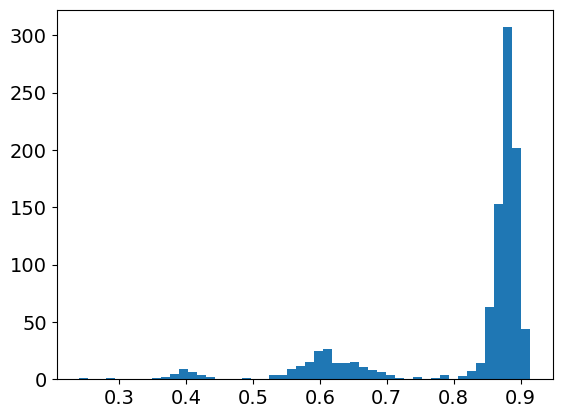

In [416]:
cors=[]
for i,j in enumerate(h):
    y= (mapping_orig(dediag(JS_200_1[j][:200,:200])))
    x = (dediag(JS_100_1[i][:100,:100]))
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


/tmp/ipykernel_114487/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
/home/benedetta/miniconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/benedetta/miniconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


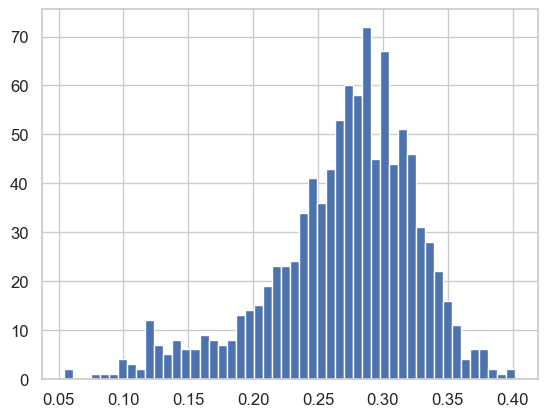

In [627]:
cors=[]
for i,j in enumerate(h):
    y= cluster_regions_EC(mapping_try_new(dediag(JS_200_1[j][:200,:200])), aggregate[:100])
    x = cluster_regions_EC(dediag(JS_100_1[i][:100,:100]), aggregate[:100])
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


/tmp/ipykernel_114487/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


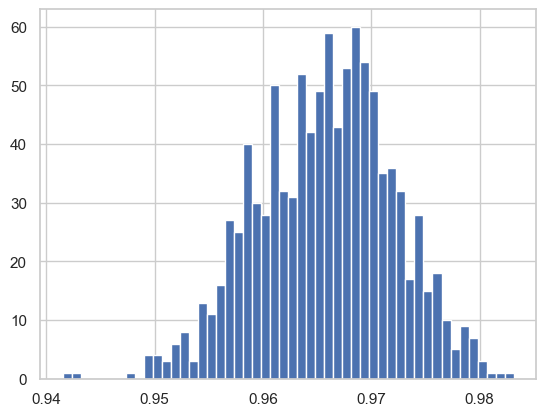

In [243]:
cors=[]

for i,j in enumerate(np.arange(0,1013,1)):
    y= dediag(cluster_regions_EC(JS_100_1[j][:100,:100], aggregate[:100]))
    x = dediag(JS[i][:62,:62])
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


In [125]:
np.corrcoef(dediag(cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100])).flatten(), dediag(JS[subject,:62,:62]).flatten())


/tmp/ipykernel_114487/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


array([[1.        , 0.96281833],
       [0.96281833, 1.        ]])

In [141]:
dediag(cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])).shape

/tmp/ipykernel_114487/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


(62, 62)

In [144]:
#x = zscore(dediag(mapping_100_200(JS_200_1[subject][:200,:200])))
#y = zscore(dediag((JS_100_1[subject][:100,:100])))
np.corrcoef(dediag(cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100])).flatten(), dediag(JS[subject,:62,:62]).flatten())

/tmp/ipykernel_114487/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


array([[1.        , 0.96281833],
       [0.96281833, 1.        ]])

In [431]:
c1 =[]
for i in range(len(js_mean)):
    c1.append(np.corrcoef(dediag(js_mean[i]).flatten(),dediag(JS_72[i]).flatten())[0,1])
c2 =[]
for i in range(len(js_mean)):
    c2.append(np.corrcoef(dediag(js_mean_2[i]).flatten(),dediag(JS_2_72[i]).flatten())[0,1])

In [433]:
np.mean(c1), np.mean(c2)

(np.float64(0.9662494649143201), np.float64(0.9647149838513821))

In [420]:

js =[]


js.append(dediag(np.mean(JS[:][:,:62,:62],0)))
js.append(dediag(np.mean(JS_100_1[:,:100,:100],0)))
js.append(dediag(np.mean(JS_new[:,:200,:200],0)))# np.mean(JS[:,:62,:62],0))
len(js)
js.append(js[0])
js.append(cluster_regions_EC(js[1], aggregate[:100]))
js.append(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100]))
len(js)



/tmp/ipykernel_54028/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


6

1.0 1.0
0.6505131218030457 0.97
0.2901681935220141 0.92


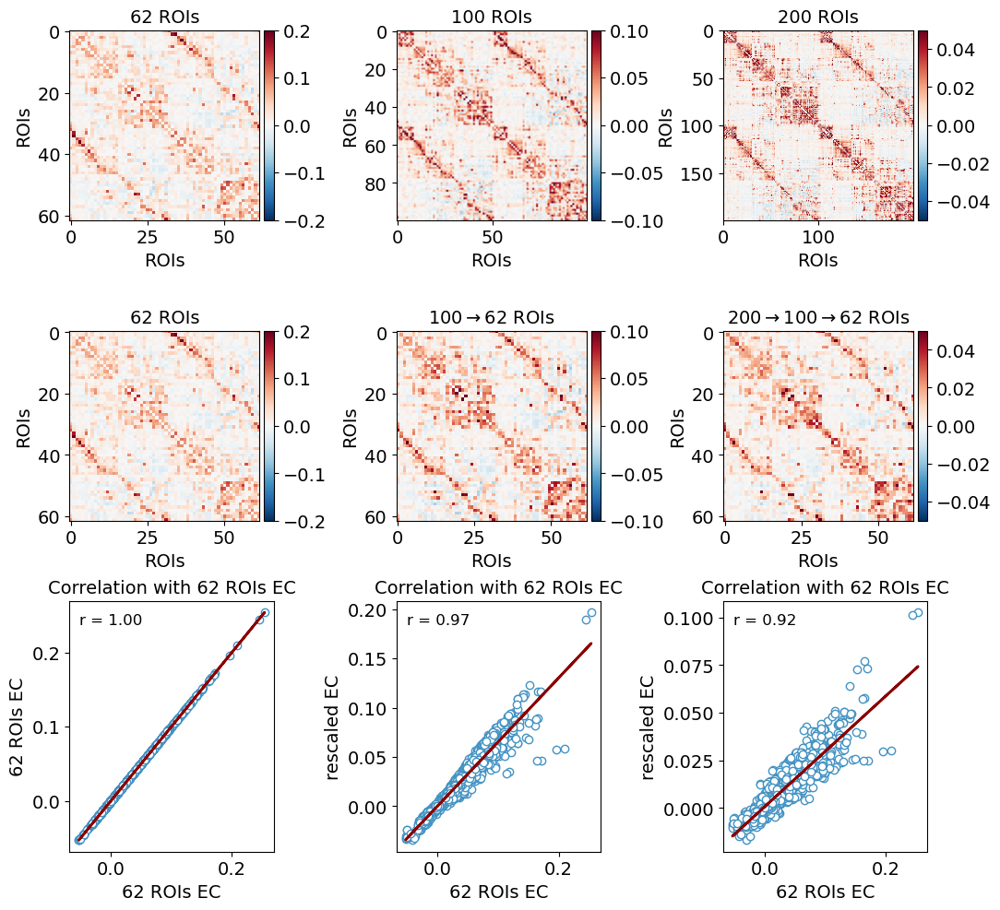

In [423]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(3, 3, figsize=(12,12), )
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 15

#plt.rcParams["axes.titlesize"] = 14
#plt.rcParams["axes.labelsize"] = 12
#plt.rcParams["xtick.labelsize"] = 12
#plt.rcParams["ytick.labelsize"] = 12



# Primo pannello
v = [0.2,0.1,0.05, 0.2,0.1,0.05]



#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['62 ROIs', '100 ROIs', '200 ROIs', '62 ROIs', r'$100 \rightarrow 62$ ROIs', r'$200 \rightarrow 100 \rightarrow 62 $ ROIs', 
         'Correlation with 62 ROIs EC','Correlation with 62 ROIs EC', 'Correlation with 62 ROIs EC']
for i,ax in enumerate(axes.reshape(-1)[:6]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}")
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    



from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore


#print(i)

# Dati


for i,ax in enumerate(axes.reshape(-1)[6:]):

    x = (dediag(js[0]))
    y = (dediag(js[i+3]))
    im= ax.scatter(x,y,c = 'white',edgecolor = colors_11[8]
                  )#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
    res = linregress(x.flatten(), y.flatten())
    slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue

    y_line = slope * x.flatten() + intercept
    ax.plot(x.flatten(), y_line, linewidth=2, color ='darkred')
    print(slope, r)
    from scipy import stats
    #res = stats.spearmanr(x.flatten(), y.flatten())
    # Titolo completo
    #print('sp', res)
    ax.set_title(f"{titles[i+6]}")
    ax.set_xlabel('62 ROIs EC')
    ax.set_ylabel('62 ROIs EC') if i == 0 else ax.set_ylabel('rescaled EC') 
    
    # --- Testo dentro la figura ---
    text_str = f"r = {r:.2f}"
    ax.text(
        0.05, 0.95,              # posizione (fractions dell'asse)
        text_str,
        transform=ax.transAxes,  # usa coordinate normalizzate
        verticalalignment='top',
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
    
#plt.tight_layout()  
plt.subplots_adjust(wspace=0.6, hspace=0.2)
plt.savefig('Figures/Av Coarse graining.jpg', bbox_inches ='tight', dpi = 300)

In [442]:
len([[js[0],js[0+3]], [js[0],js[0+4]],[js[0],js[0+5]], None,None,None,None,[js[1],js[0+6]], None, None,None, None])

12

/tmp/ipykernel_54028/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


1.0 1.0
0.6505131218030457 0.97
0.2901681935220141 0.92
0.4625078678902167 0.94


/tmp/ipykernel_54028/112738722.py:130: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.6, hspace=0.1)


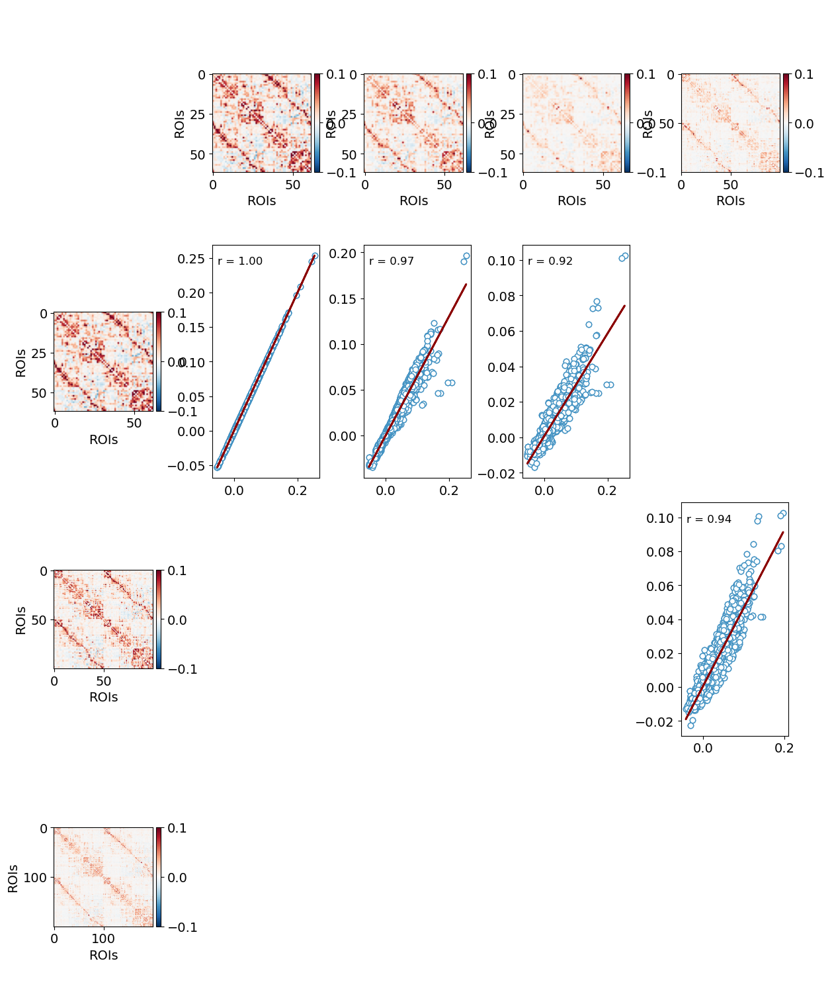

In [450]:
v# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(4, 5, figsize=(12,15), constrained_layout =True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 15

js =[]


js.append(dediag(np.mean(JS[:][:,:62,:62],0)))
js.append(dediag(np.mean(JS_100_1[:,:100,:100],0)))
js.append(dediag(np.mean(JS_new[:,:200,:200],0)))# np.mean(JS[:,:62,:62],0))
len(js)
js.append(js[0])
js.append(dediag(cluster_regions_EC(js[1], aggregate[:100])))
js.append(dediag(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100])))
js.append(dediag(mapping_orig(js[2])))

len(js)




# Primo pannello
v = [0.2,0.1,0.05, 0.2,0.1,0.05]



#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

#titles = ['62 ROIs', '100 ROIs', '200 ROIs', '62 ROIs', r'$100 \rightarrow 62$ ROIs', r'$200 \rightarrow 100 \rightarrow 62 $ ROIs', 
 #        'Correlation with 62 ROIs EC','Correlation with 62 ROIs EC', 'Correlation with 62 ROIs EC']
#for i,ax in enumerate(axes.reshape(-1)[:6]):
for i,ax in enumerate([axes[1,0],axes[2,0], axes[3,0],axes[0,1],axes[0,2], axes[0,3],axes[0,4]]):
    im= ax.imshow(js[i], vmin=-0.1, vmax=0.1, cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"")
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    



from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore


#print(i)

# Dati
n = 0

mat=  [[js[0],js[0+3]], [js[0],js[0+4]],[js[0],js[0+5]], None,None,None,None,[js[1],js[0+6]],None,None,None,None ]
for i in range(1,axes.shape[0]):
    for j in range(1,axes.shape[1]):
        if mat[n] is not None:
            axes[i,j].scatter(mat[n][0].flatten(), mat[n][1].flatten())

            ax = axes[i,j]
                    
            x = mat[n][0]
            y = mat[n][1]
            im= ax.scatter(x,y,c = 'white',edgecolor = colors_11[8]
                          )#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
            res = linregress(x.flatten(), y.flatten())
            slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue
        
            y_line = slope * x.flatten() + intercept
            ax.plot(x.flatten(), y_line, linewidth=2, color ='darkred')
            print(slope, r)
            from scipy import stats
            #res = stats.spearmanr(x.flatten(), y.flatten())
            # Titolo completo
            #print('sp', res)
            #ax.set_title(f"{titles[i+6]}")
            #ax.set_xlabel('62 ROIs EC')
            #ax.set_ylabel('62 ROIs EC') if i == 0 else ax.set_ylabel('rescaled EC') 
            
            # --- Testo dentro la figura ---
            text_str = f"r = {r:.2f}"
            ax.text(
                0.05, 0.95,              # posizione (fractions dell'asse)
                text_str,
                transform=ax.transAxes,  # usa coordinate normalizzate
                verticalalignment='top',
                fontsize=12,
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
            )
        else:
            axes[i,j].axis('off')
        n+=1
axes[0,0].axis('off')
"""
for i,ax in enumerate(axes.reshape(-1)[6:]):

    x = (dediag(js[0]))
    y = (dediag(js[i+3]))
    im= ax.scatter(x,y,c = 'white',edgecolor = colors_11[8]
                  )#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
    res = linregress(x.flatten(), y.flatten())
    slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue

    y_line = slope * x.flatten() + intercept
    ax.plot(x.flatten(), y_line, linewidth=2, color ='darkred')
    print(slope, r)
    from scipy import stats
    #res = stats.spearmanr(x.flatten(), y.flatten())
    # Titolo completo
    #print('sp', res)
    ax.set_title(f"{titles[i+6]}")
    ax.set_xlabel('62 ROIs EC')
    ax.set_ylabel('62 ROIs EC') if i == 0 else ax.set_ylabel('rescaled EC') 
    
    # --- Testo dentro la figura ---
    text_str = f"r = {r:.2f}"
    ax.text(
        0.05, 0.95,              # posizione (fractions dell'asse)
        text_str,
        transform=ax.transAxes,  # usa coordinate normalizzate
        verticalalignment='top',
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )


#plt.tight_layout()  
"""
plt.subplots_adjust(wspace=0.6, hspace=0.1)
#"""
#plt.savefig('Figures/Av Coarse graining.jpg', bbox_inches ='tight', dpi = 300)

In [104]:
JS.shape, JS_100_1.shape, JS_200_1.shape

((1013, 74, 74), (1013, 112, 112), (1024, 212, 212))

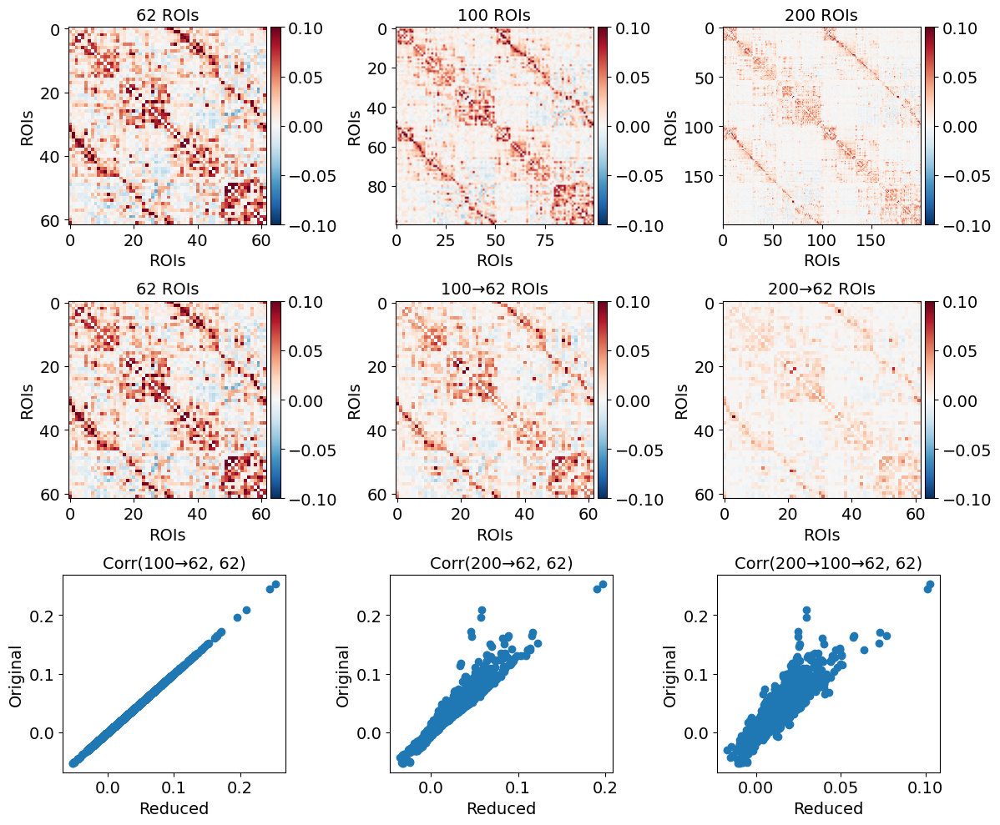

In [451]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

# Simuliamo i dati per esempio
# js[0] = 62x62, js[1] = 100x100, js[2] = 200x200
# js[3:] = versioni ridotte / trasformate


# Crea figura 3x3
fig, axes = plt.subplots(3, 3, figsize=(12,10))
vmin, vmax = -0.1, 0.1
titles_heatmap = ['62 ROIs', '100 ROIs', '200 ROIs']
titles_reduced = ['62 ROIs', '100→62 ROIs', '200→62 ROIs']
titles_scatter = ['Corr(100→62, 62)', 'Corr(200→62, 62)', 'Corr(200→100→62, 62)']

# Heatmap originali
for i in range(3):
    im = axes[0,i].imshow(js[i], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[0,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[0,i].set_title(titles_heatmap[i])
    axes[0,i].set_xlabel('ROIs')
    axes[0,i].set_ylabel('ROIs')

# Heatmap ridotte
for i in range(3):
    im = axes[1,i].imshow(js[i+3], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[1,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[1,i].set_title(titles_reduced[i])
    axes[1,i].set_xlabel('ROIs')
    axes[1,i].set_ylabel('ROIs')

# Scatter plot correlazioni
for i in range(3):
    axes[2,i].scatter(js[i+3].flatten(), js[0].flatten())
    axes[2,i].set_title(titles_scatter[i])
    axes[2,i].set_xlabel('Reduced')
    axes[2,i].set_ylabel('Original')

plt.tight_layout()
plt.show()


In [452]:
len(js)

7

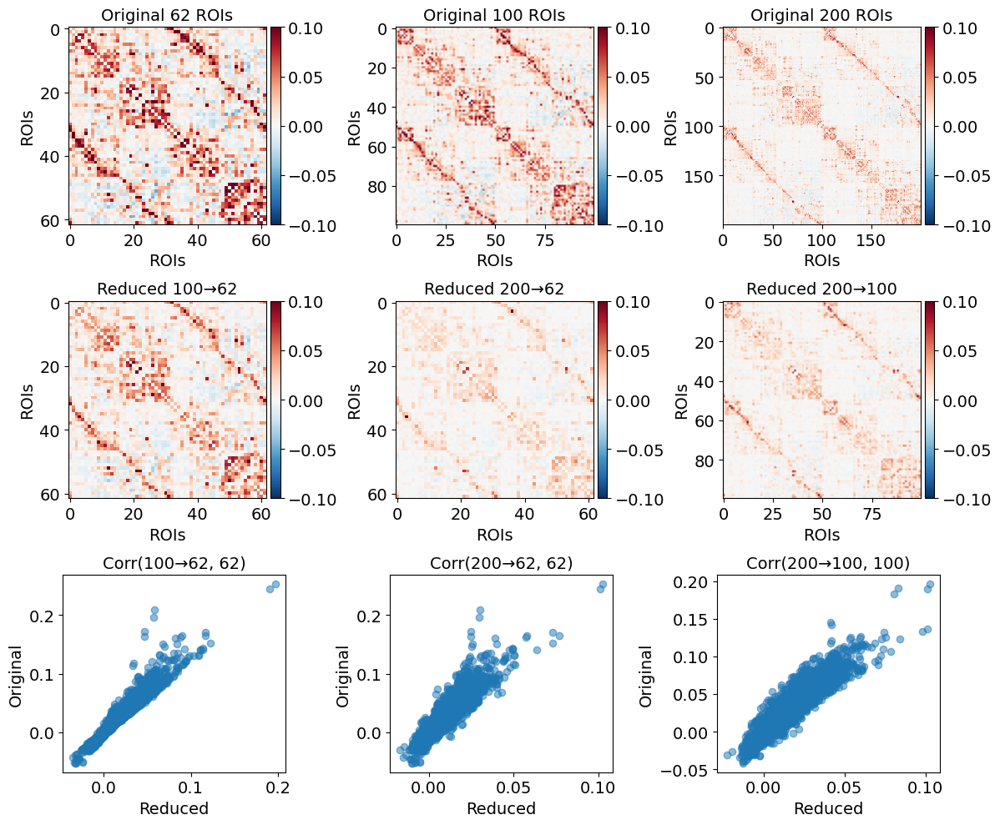

In [476]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

# Simuliamo i dati
js_original = js[:3]

js_reduced = js[3:]


# Crea figura 3x3
fig, axes = plt.subplots(3, 3, figsize=(12,10))
vmin, vmax = -0.1, 0.1

# Heatmap originali
for i in range(3):
    im = axes[0,i].imshow(js_original[i], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[0,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[0,i].set_title(f'Original {["62","100","200"][i]} ROIs')
    axes[0,i].set_xlabel('ROIs')
    axes[0,i].set_ylabel('ROIs')

# Heatmap ridotte
for i in range(3):
    im = axes[1,i].imshow(js_reduced[i], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[1,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[1,i].set_title(f'Reduced {["100→62","200→62","200→100"][i]}')
    axes[1,i].set_xlabel('ROIs')
    axes[1,i].set_ylabel('ROIs')

# Scatter correlazioni
corr_pairs = [(js_reduced[0], js_original[0]),  # 100->62 vs 62
              (js_reduced[1], js_original[0]),  # 200->62 vs 62
              (js_reduced[2], js_original[1])]  # 200->100 vs 100

titles_scatter = ['Corr(100→62, 62)','Corr(200→62, 62)','Corr(200→100, 100)']

for i, (x,y) in enumerate(corr_pairs):
    axes[2,i].scatter(x.flatten(), y.flatten(), alpha=0.5)
    axes[2,i].set_title(titles_scatter[i])
    axes[2,i].set_xlabel('Reduced')
    axes[2,i].set_ylabel('Original')

plt.tight_layout()


plt.savefig('Figures/Pairplot.jpg', bbox_inches ='tight', dpi = 300)

plt.show()


In [495]:
np.percentile(js[0],98)

np.float64(0.09800117412010377)

/tmp/ipykernel_54028/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


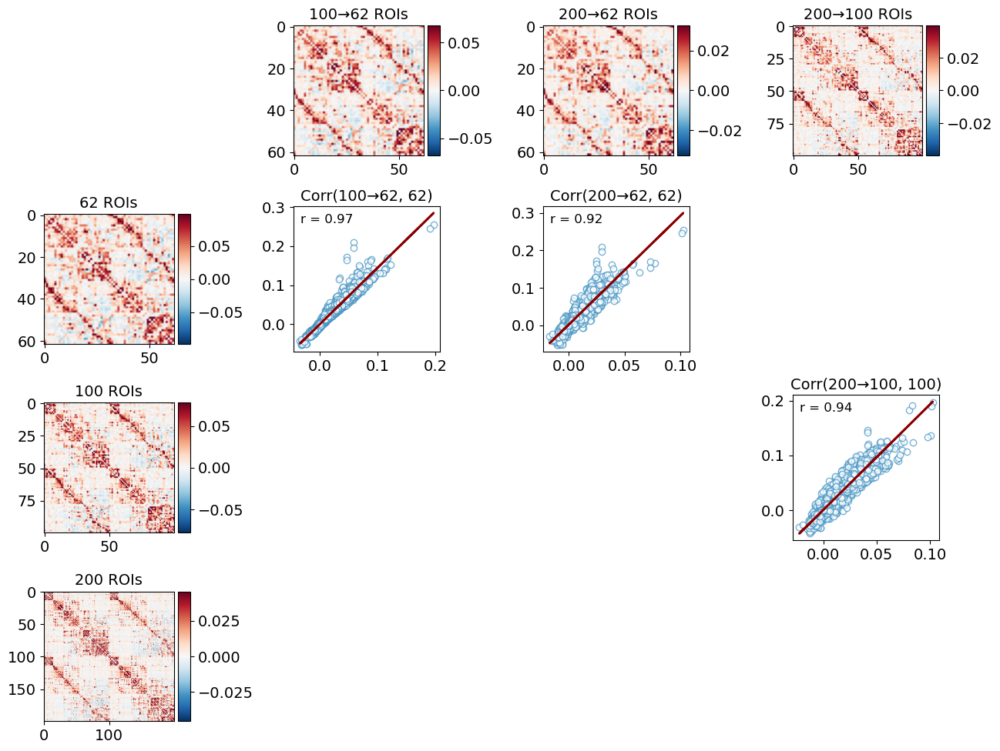

In [496]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

# Simuliamo i dati
js =[]

js.append(dediag(np.mean(JS[:][:,:62,:62],0)))
js.append(dediag(np.mean(JS_100_1[:,:100,:100],0)))
js.append(dediag(np.mean(JS_new[:,:200,:200],0)))# np.mean(JS[:,:62,:62],0))

js.append(dediag(cluster_regions_EC(js[1], aggregate[:100])))
js.append(dediag(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100])))
js.append(dediag(mapping_orig(js[2])))

matrices = js
import matplotlib.pyplot as plt
import numpy as np


orig_labels = ['62 ROIs', '100 ROIs', '200 ROIs']
reduced_labels = ['100→62 ROIs', '200→62 ROIs', '200→100 ROIs']


n_orig = len(original)
n_red = len(reduced)

# Colori per scatter
#colors_11 = plt.cm.tab20.colors

n_orig = len(original)
n_red = len(reduced)


# Creiamo gridspec con spazio uniforme per tutte le celle
fig = plt.figure(figsize=(15,12))
gs = fig.add_gridspec(n_orig+1, n_red+1, 
                      width_ratios=[1]+[1]*n_red,
                      height_ratios=[1]+[1]*n_orig,
                      hspace=0.3, wspace=0.7)
ax = fig.add_subplot(gs[0,0])
ax.axis('off')
# Heatmap in alto (ridotti)
for j, red_mat in enumerate(reduced):
    ax = fig.add_subplot(gs[0,j+1])
    im = ax.imshow(red_mat, vmin=-np.percentile(red_mat,98), vmax=np.percentile(red_mat,98), cmap='RdBu_r')
    # Colorbar dentro la stessa cella, piccola
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)
    ax.set_title(reduced_labels[j])

# Heatmap a sinistra (originali)
for i, orig_mat in enumerate(original):

    ax = fig.add_subplot(gs[i+1,0])
    im = ax.imshow(orig_mat, vmin=-np.percentile(orig_mat,98), vmax=np.percentile(orig_mat,98), cmap='RdBu_r')
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)
    ax.set_title(orig_labels[i])

titles_scatter = ['Corr(100→62, 62)','Corr(200→62, 62)','Corr(200→100, 100)']
n=0
# Scatter plot interni con regressione e r
for i, orig_mat in enumerate(original):
    for j, red_mat in enumerate(reduced):
        ax = fig.add_subplot(gs[i+1,j+1])
        if orig_mat.shape == red_mat.shape:
            x = red_mat
            y = orig_mat
            ax.scatter(x, y, c='white', edgecolor=colors_11[8], alpha=0.7)
            res = linregress(x.flatten(), y.flatten())
            slope, intercept, r, p = res.slope, res.intercept, res.rvalue, res.pvalue
            y_line = slope * x.flatten() + intercept
            ax.plot(x.flatten(), y_line, color='darkred', linewidth=2)
            ax.text(0.05,0.95, f"r = {r:.2f}", transform=ax.transAxes,
                    verticalalignment='top', fontsize=12,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
            ax.set_title(titles_scatter[n])
            n+=1
        else:
            ax.axis('off')
        ax.set_xlabel('')
        ax.set_ylabel('')
#plt.tight_layout()
#plt.show()
#plt.savefig('Figures/Pairplot.jpg', bbox_inches ='tight', dpi = 300)


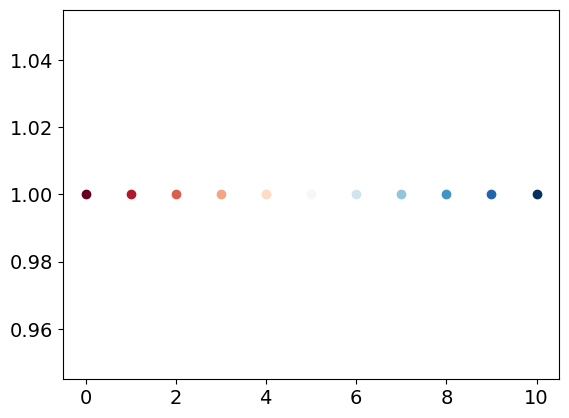

In [516]:

for i in range(11):
    plt.plot(i,1,'o',color=colors_11[i])

In [573]:
len(list(set(sub_tot_) - set(sub_tot) ))

11

In [574]:
[np.where(list(set(sub_tot_) - set(sub_tot) )[i] == sub_tot_)[0] for i in range(11)]

[array([564]),
 array([687]),
 array([324]),
 array([873]),
 array([191]),
 array([386]),
 array([802]),
 array([232]),
 array([283]),
 array([91]),
 array([90])]

/tmp/ipykernel_54028/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
/tmp/ipykernel_54028/472709309.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


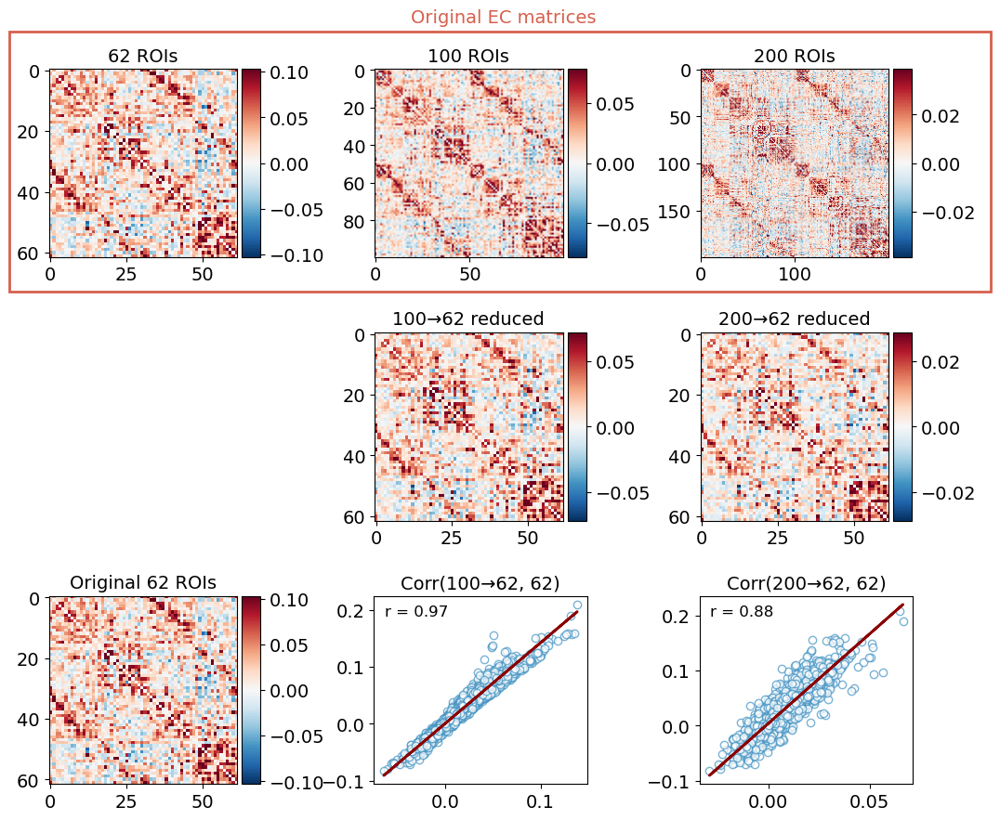

In [577]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from scipy.stats import linregress
import matplotlib.patches as patches


import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from scipy.stats import linregress
import matplotlib.patches as patches


subject = 800
# Simuliamo i dati
js =[]

js.append(dediag((JS[subject,:62,:62])))
js.append(dediag((JS_100_1[subject,:100,:100])))
js.append(dediag((JS_200_1[h][subject,:200,:200])))# np.mean(JS[:,:62,:62],0))

js.append(dediag(cluster_regions_EC(js[1], aggregate[:100])))
js.append(dediag(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100])))
js.append(dediag(mapping_orig(js[2])))



# Dati simulati
original = js[:3]

reduced = js[3:]

#colors_11 = plt.cm.tab20.colors
reduced_100_62 = js[3]
reduced_200_62 = js[4]

fig, axes = plt.subplots(3,3, figsize=(12,10),
                         gridspec_kw={'height_ratios':[1,1,1], 'width_ratios':[1,1,1],
                                      'hspace':0.4, 'wspace':0.53})

# ----------------------------
# RIGA 1: matrici originali con contorno globale
# ----------------------------

fig.text(0.45,.93,s='Original EC matrices', color =colors_11[2], fontsize=14)

for j, mat in enumerate(original):
    ax = axes[0,j]

    im = ax.imshow(mat, cmap='RdBu_r', vmin=-np.percentile(mat,98), vmax=np.percentile(mat,98))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)
    ax.set_title(f"{['62 ROIs','100 ROIs','200 ROIs'][j]}")
    #ax.axis('off')
    



# rettangolo globale per tutta la prima riga
rect = patches.Rectangle(
    (0.09, 0.64),  # posizione in coordinate figura (x0, y0)
    0.88,            # larghezza
    0.28,           # altezza
    fill = False ,
    edgecolor=colors_11[2], 
    alpha=1,
    linewidth=2, 
    transform=fig.transFigure, 
    clip_on=False, zorder =0
)
fig.patches.append(rect)

# ----------------------------
# RIGA 2: heatmap ridotte
# ----------------------------
axes[1,0].axis('off')  # primo pannello vuoto
for j, mat in enumerate([reduced_100_62, reduced_200_62], start=1):
    ax = axes[1,j]
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-np.percentile(mat,98), vmax=np.percentile(mat,98))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)

    ax.set_title(['100→62 reduced','200→62 reduced'][j-1])
    

# ----------------------------
# RIGA 3: heatmap + scatter
# ----------------------------
# primo pannello: 62 originale
ax = axes[2,0]
im = ax.imshow(original[0], cmap='RdBu_r', vmin=-np.percentile(original[0],98), vmax=np.percentile(original[0],98))
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='10%', pad=0.05)
plt.colorbar(im, cax=cax)
ax.set_title('Original 62 ROIs')


# secondo pannello: scatter 62 vs 100->62
ax = axes[2,1]
x = reduced_100_62
y = original[0]
ax.scatter(x, y, c='white', edgecolor=colors_11[8], alpha=0.7)
res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, res.rvalue, res.pvalue
y_line = slope*x.flatten() + intercept
ax.plot(x.flatten(), y_line, color='darkred', linewidth=2)
ax.text(0.05,0.95, f"r = {r:.2f}", transform=ax.transAxes,
        verticalalignment='top', fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

titles_scatter = ['Corr(100→62, 62)','Corr(200→62, 62)','Corr(200→100, 100)']
ax.set_title(titles_scatter[0])
ax.set_xlabel('')
ax.set_ylabel('')

# terzo pannello: scatter 62 vs 200->62
ax = axes[2,2]
x = reduced_200_62
y = original[0]
ax.scatter(x, y, c='white', edgecolor=colors_11[8], alpha=0.7)
res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, res.rvalue, res.pvalue
y_line = slope*x.flatten() + intercept
ax.plot(x.flatten(), y_line, color='darkred', linewidth=2)
ax.text(0.05,0.95, f"r = {r:.2f}", transform=ax.transAxes,
        verticalalignment='top', fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title(titles_scatter[1])

ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout()
#plt.show()
#plt.savefig('Figures/Pairplot.jpg', bbox_inches ='tight', dpi = 300)


In [604]:
JS_100_1.shape

(1013, 112, 112)

## ttest a livello di gruppo

Numero di link significativi: 25842


np.float64(0.4250177999288003)

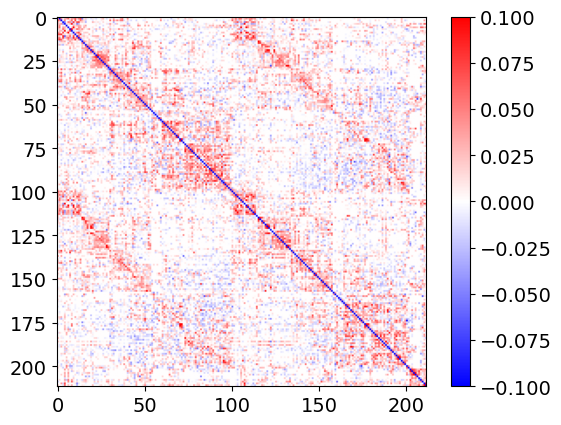

In [616]:
import numpy as np
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests

# JS.shape = (1013, 74, 74)
mat = JS_new
n_subjects, n_nodes, _ = mat.shape

t_values, p_values = ttest_1samp(mat, popmean=0, axis=0)  # shape (74, 74)

p_flat = p_values.flatten()
reject, p_corrected, _, _ = multipletests(p_flat, method='bonferroni')
significant_mask = reject.reshape((n_nodes, n_nodes))

JS_significant = np.zeros((n_nodes, n_nodes))
JS_significant[significant_mask] = 1

print("Numero di link significativi:", np.sum(significant_mask))


prova = mat[0].copy()
prova[np.logical_not(significant_mask)]=0
plt.imshow(prova, cmap ='bwr', vmin=-.1, vmax=.1);
#plt.imshow(significant_mask, cmap ='binary',alpha=.1);

plt.colorbar()

(prova==0).sum()/ (np.abs(mat[0])>0).sum()

In [563]:
# fare t test a lviello di gruppo per sparsificare




1013

In [223]:
JS_new = np.delete(JS_new,indici_,0)
#JS_new_2 = np.delete(JS_new_2,indici_,0)

In [227]:
JS_200_2 = np.load('numpy files/EC_matrix_HCP2_200.npy')
#JS_200_2 = 
set2=(np.where(np.array(list(map(np.sum, np.array(list(map(dediag, JS_200_1))))))==0)[0])
set1=(np.where(np.array(list(map(np.sum, np.array(list(map(dediag, JS_200_2))))))==0)[0])
indici = np.asarray(list(set(set1) | set(set2)))
indici

array([ 256,  897,    2,  706,    5,  198,  202,  911,  410,  154,   30,
        864,  609,  738,  675, 1006,  763,  444])

In [332]:
JS_new = np.delete(JS_200_1,indici,0)
JS_new_2 = np.delete(JS_200_2,indici,0)

In [336]:
JS_new.shape

(1006, 212, 212)

In [334]:
l = []
for i in range(JS_new.shape[0]):
    #print(i)
    if np.max(JS_new[i])<0.02:
        l.append(i)
        #print(i,np.sum(dediag(JS_new[i])))
        
indici = (np.unique(l))
print(indici.shape)

#print(np.max(JS[379])<0.02)

l = []
for i in range(JS_new_2.shape[0]):
    if np.max(JS_new_2[i])<0.02:
        l.append(i)
        #print(i,np.sum(dediag(JS_new_2[i])))
indici2 = (np.unique(l))
print(indici2.shape)


(167,)
(126,)


In [335]:
indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)

(253, 167, 126)

In [337]:
JS_new = np.delete(JS_new,indici_,0)
JS_new_2 = np.delete(JS_new_2,indici_,0)

In [338]:
JS_new.shape

(753, 212, 212)

In [230]:
#JS_100_1.shape
JS_100_2 = np.load('numpy files/EC_matrix_HCP2_100.npy')
JS_100_2.shape


#JS_100_1.shape
JS_100_1 = np.load('numpy files/EC_matrix_HCP1_100.npy')
JS_100_2.shape


#JS_100_1.shape
JS_200_2 = np.load('numpy files/EC_matrix_HCP2_200.npy')
JS_200_2.shape


#JS_100_1.shape
JS_200_1 = np.load('numpy files/EC_matrix_HCP1_200.npy')
JS_100_2.shape

(1013, 112, 112)

## Fingerprinting figure

### calcolo fc

In [3]:
from my_module import *
import os
from scipy import signal
from tqdm import tqdm

In [10]:
#rcellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)
            #print('here')
len(sub_tot)

100%|██████████| 1097/1097 [00:09<00:00, 117.92it/s]


1013

In [25]:
fc_2=[]
l=0
nparcel=200 # IMPO 100 SE POI E USO 72 
#JS_2 =[]
pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))

if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
for sub in tqdm(sub_tot):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        #data_ref = data_1
        Y =data_ref[:,:nparcel]
        #Y =
        #cluster_regions(data_ref[:,:100],aggregate[:100])
        
        #cluster_regions(data_ref[:,:100],aggregate[:100])
        #m = MOU()
        Q0 = calc_Corr0(Y)
        Q1 = calc_Corrlag(Y,1)
        """
        m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=.7,eta_C =0.005,max_iter = 1000)
        J_prior =m.J;

        if np.sum(dediag(J_prior))==0:
        
            m = MOU()
            Q0 = calc_Corr0(Y)
            Q1 = calc_Corrlag(Y,1)
            m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.,eta_C =0.005,max_iter =1000)
            J_prior =m.J;
            print(np.sum(dediag(J_prior)))
            
        """
        #JS_2.append(J_prior)
    
        fc_2.append(Q0)

        #sub_tot.append(sub)
    else:
        l+=1


100%|██████████| 1013/1013 [00:25<00:00, 39.57it/s]


In [15]:
#JS_1_62 = np.load('../numpy files/EC_matrix_HCP1_74.npy')[:,:62,:62]
#JS_2_62 = np.load('../numpy files/EC_matrix_HCP2_74.npy')[:,:62,:62]
JS_1_100 = np.load('../numpy files/JS_1_100_new.npy')
JS_2_100 = np.load('../numpy files/JS_2_100_new.npy')
print(JS_1_100.shape)

JS_1_200 = np.load('../numpy files/JS_1_200_new.npy')
JS_2_200 = np.load('../numpy files/JS_2_200_new.npy')
print(JS_1_200.shape)

(1013, 100, 100)
(1013, 200, 200)


In [15]:
len(Q0)

62

In [26]:
fc_1=[]
l=0
#JS = []
#sub_tot =[]
#JS = JS[:911]
#JS =JS.tolist()
#nparcel=200 # IMPO 100 SE POI E USO 72 

if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
    
for sub in tqdm(sub_tot[:]):
    if os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        #data_ref = data_1
        #
        Y =(data_ref[:,:nparcel])#,aggregate[:100])
        #Y = data_ref[:,:nparcel]
        #cluster_regions(data_ref[:,:100],aggregate[:100])
        #m = MOU()
        Q0 = calc_Corr0(Y)
        Q1 = calc_Corrlag(Y,1)
        """
        try:
            m.fit_LO(Q0,Q1,lag = 1,prior =0.,tau=.7, eta_C=0.005,max_iter = 1000)
            J_prior = m.J;
            if np.sum(dediag(J_prior))==0:
                m = MOU()
                Q0 = calc_Corr0(Y)
                Q1 = calc_Corrlag(Y,1)
                m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.,eta_C =0.005,max_iter = 1000)
                J_prior =m.J;
                print(np.sum(dediag(J_prior)))
        except:
            J_prior = np.zeros((Q0.shape[0],Q0.shape[0]))
            print('exception')
         
        if np.sum(dediag(J_prior))>269 or np.sum(dediag(J_prior))==0:
        
            m = MOU()
            Q0 = calc_Corr0(Y)
            Q1 = calc_Corrlag(Y,1)
            m.fit_LO(Q0,Q1,lag = 1,prior =0., tau=1.1,eta_C =0.005,max_iter = 1000)
            J_prior =m.J;
            print('2nd try', np.sum(dediag(J_prior)))
        
        """
        #JS.append(J_prior)
        Q0 = calc_Corr0(Y)
        fc_1.append(Q0)
    else:
        l+=1


100%|██████████| 1013/1013 [00:29<00:00, 34.05it/s]


In [19]:
np.asarray(fc_2).shape

(1013, 62, 62)

In [20]:
fc_1_62, fc_2_62 = np.asarray(fc_1[:]), np.asarray(fc_2[:])
print(fc_1_62.shape, fc_2_62.shape)

(1013, 62, 62) (1013, 62, 62)


In [24]:
fc_1_100,fc_2_100= np.asarray(fc_1), np.asarray(fc_2)
print(fc_1_100.shape, fc_2_100.shape)

(1013, 100, 100) (1013, 100, 100)


In [28]:
fc_1_200,fc_2_200= np.asarray(fc_1), np.asarray(fc_2)
print(fc_1_200.shape, fc_2_200.shape)

(1013, 200, 200) (1013, 200, 200)


In [22]:
JS_1_100 = np.load('numpy files/EC_matrix_HCP1_100.npy')
    #[:,:100,:100]
JS_2_100 = np.load('numpy files/EC_matrix_HCP2_100.npy')
    #[:,:100,:100]
print(JS_1_100.shape)

#JS_1_100 = np.load('numpy files/JS_1_100_new.npy')
#JS_2_100 = np.load('numpy files/JS_2_100_new.npy')
print(JS_1_100.shape)



(1013, 112, 112)
(1013, 112, 112)


In [1]:
import numpy as np

(1013, 100, 100)
(1013, 200, 200)


(40,)
138.44210272526783
i: 0.005584267973730431
209.13469586619357
i: 0.013456653788253337
209.24585214995082
i: 0.013414208977733603
131.16661546175413
i: 0.024283016476038508
131.9624594934335
i: 0.023726657550287036
200.3077299139615
i: 0.013305803858657829
204.68137297320192
i: 0.0133754958180422
207.84774272281047
i: 0.013064427301987123
209.31534271524498
i: 0.013344783488033498
207.43763118957673
i: 0.013316028191035997
209.4089165641905
i: 0.013413268599843486
202.79836453864905
i: 0.013399660782998075
190.8991684076746
i: 0.0135135191878943
131.49161702637844
i: 0.005508949449694935
131.63908095133579
i: 0.02259875556421617
196.31135423271007
i: 0.013194359228385284
193.95682625313168
i: 0.013442587130810134
149.1462213780345
i: 0.012855736636208637
206.4988330959883
i: 0.013451953932941952
202.12493160205764
i: 0.013486196817523185
205.64696975420077
i: 0.012648444995534252


/tmp/ipykernel_135722/4039339214.py:31: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


Pearson Cor:  0.9517313746065058


((953, 200, 200), (953, 200, 200))

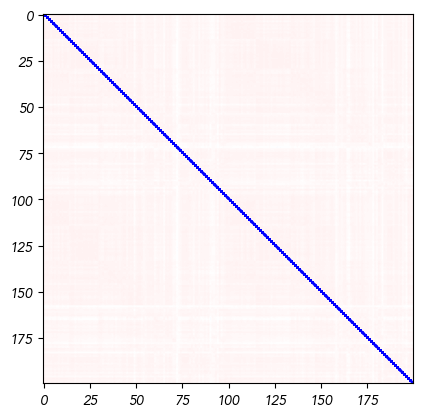

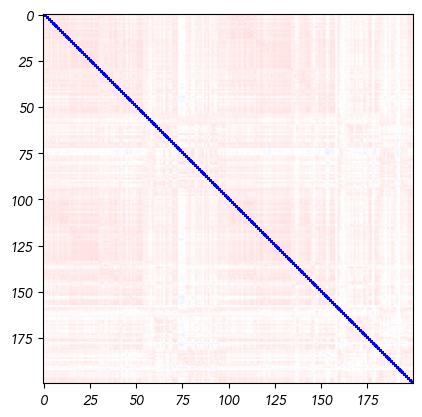

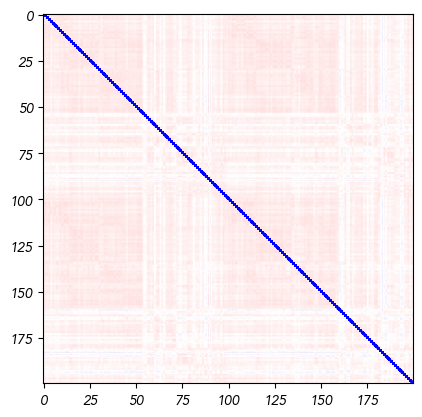

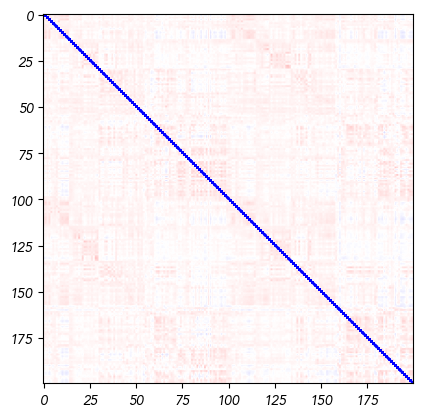

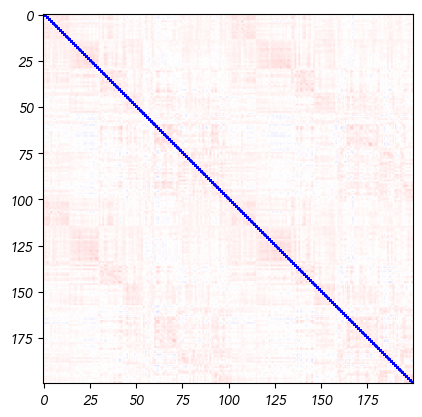

...

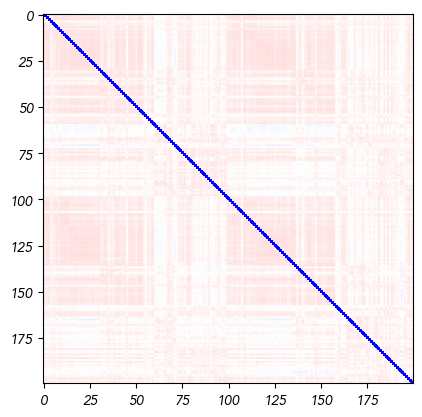

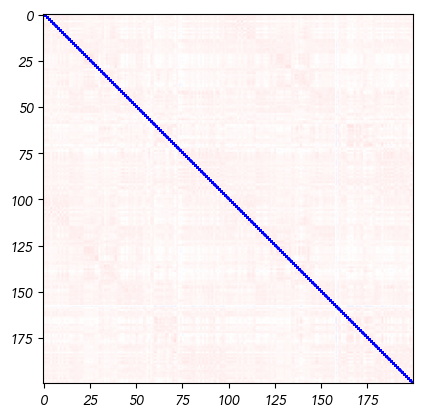

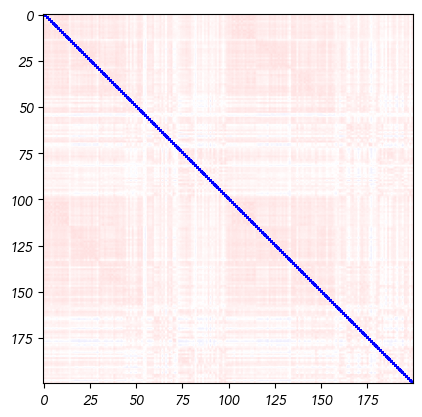

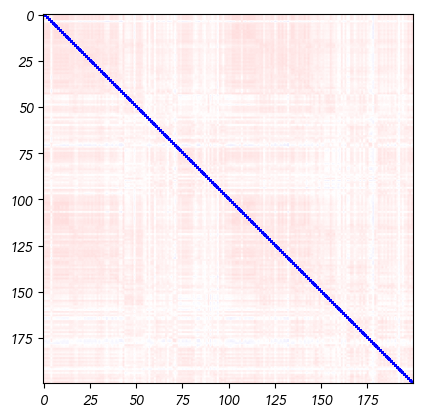

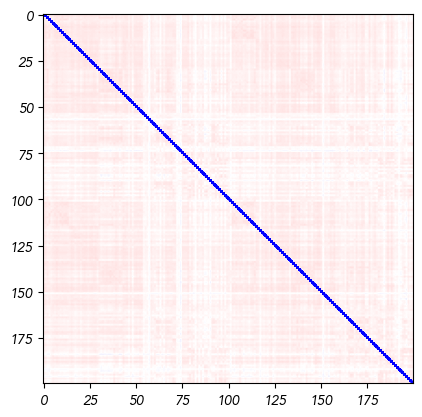

In [30]:

l = []
for i in range(JS_1_200.shape[0]):
    #print(i)
    if np.max(JS_1_200[i])<0.03:
        l.append(i)
        #print(i,np.sum(dediag(JS_new[i])))
        
indici = (np.unique(l))
print(indici.shape)

#print(np.max(JS[379])<0.02)

l = []
for i in range(JS_2_200.shape[0]):
    if np.max(JS_2_200[i])<0.03:
        l.append(i)
        #print(i,np.sum(dediag(JS_new_2[i])))
indici2 = (np.unique(l))
indici2.shape
indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)


indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)
JS_new = np.delete(JS_1_200,indici_,0)
JS_new_2 = np.delete(JS_2_200,indici_,0)

indici = np.asarray(indici)
for ii in range(len(indici2)):
    plt.figure()
    plt.imshow(JS_2_200[indici2][ii], vmin=-.1, vmax=.1, cmap ='bwr')
    print(np.sum(dediag(JS_2_200[indici2][ii])))
    print('i:', np.max(dediag(JS_2_200[indici2][ii])))
    if ii == 20:break
idx = np.triu_indices(200,0)
X1 = np.asarray([dediag(i).flatten() for i in JS_new[:]])
X2 =  np.asarray([dediag(i).flatten() for i in JS_new_2[:]])
C = np.corrcoef(np.vstack([X1,X2]))[:X1.shape[0], X1.shape[0]:]

C = np.asarray(C)
c=[]

for i in range(len(C)):
    mask = (np.isnan(C[i]))
    C[i][mask] = 0
    if np.argmax(C[i]) ==i:
        c.append(1)
    else:
        c.append(0)
print('Pearson Cor: ',np.mean(c))
#C[0]
len(indici_)
JS_new.shape, JS_new_2.shape

In [28]:
from matplotlib import cm
color = cm.Set1(np.linspace(0,1,3))
color[0]

array([0.89411765, 0.10196078, 0.10980392, 1.        ])

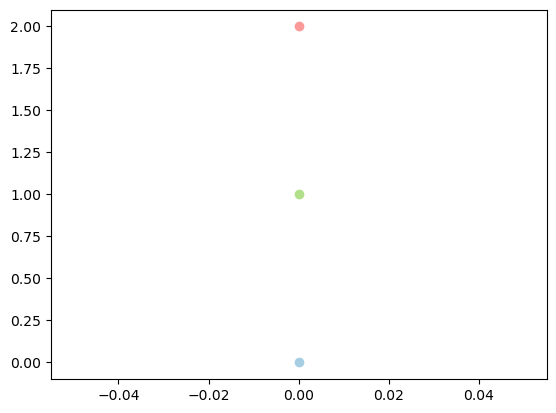

In [33]:
k  =cm.Paired(np.linspace(0,1,12))[:6]

index = np.logical_not(np.array([0,1,0,1,0,1])).astype(bool)
for i in range(len(k[index])):
    plt.plot(i,'o', color =k[index][i]);

In [31]:
plt.rcParams['font.size']=14

#sns.set_style(None)
#plt.style.use('default')

In [27]:
JS_new.shape

(953, 200, 200)

In [22]:
indic = np.array([0,1,0,1,0,1]).astype(bool)

In [664]:
plt.style.use('default')

Avenir


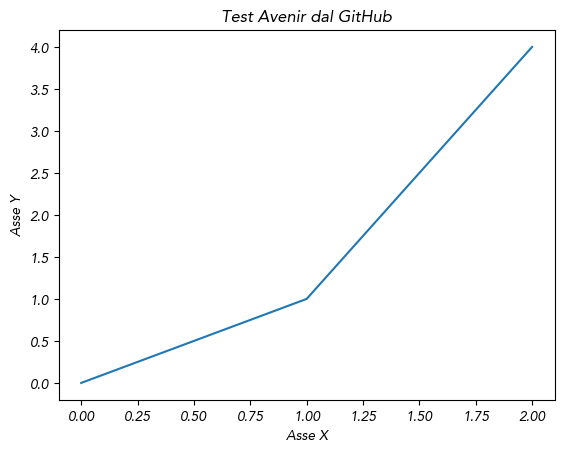

In [14]:
import urllib.request
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt

# Link diretto al file TTF su GitHub (raw)
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"

# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = font_name

# Test plot
plt.figure()
plt.title("Test Avenir dal GitHub")
plt.xlabel("Asse X")
plt.ylabel("Asse Y")
plt.plot([0, 1, 2], [0, 1, 4])

In [49]:
np.sum(np.abs(JS_1_100[0] -JS_1_100[0].T))/np.sum(np.abs(JS_1_100[0]))/2

np.float64(0.08567383291954568)

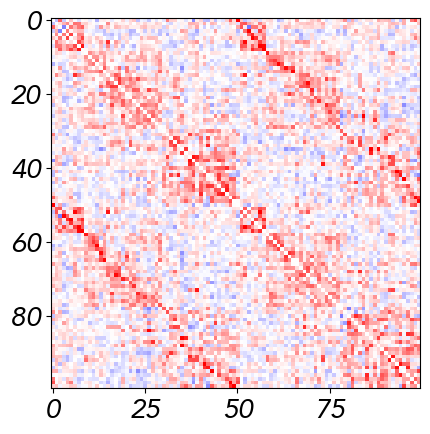

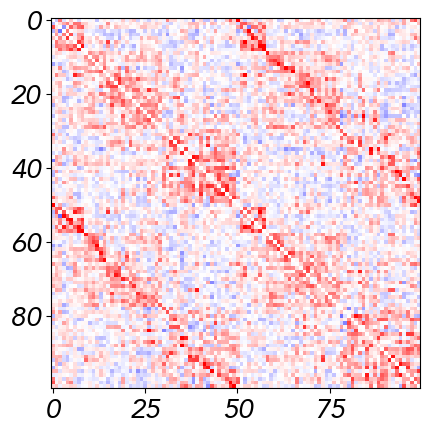

In [43]:


matrix_1 = np.asarray([(m + m.T)/2 for m in JS_1_100])
matrix_2= np.asarray([(m + m.T)/2 for m in JS_2_100])


plt.imshow(dediag(matrix_1[0]), vmin=-.1, vmax=.1, cmap='bwr');
plt.figure()
plt.imshow(dediag(JS_1_100[0]), vmin=-.1, vmax=.1, cmap='bwr');


In [25]:
plt.rcParams['font.size']= 22

(1013, 62, 62)
(1013, 100, 100)
(953, 200, 200)
(1013, 62, 62)
10
(1013, 100, 100)
10
(1013, 200, 200)
10


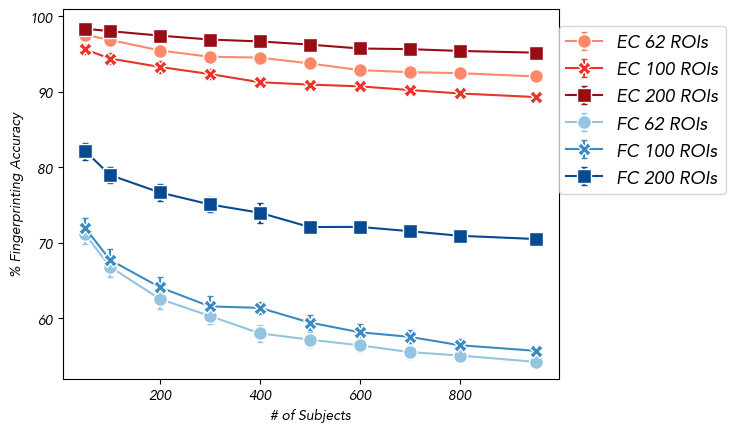

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# ==========================================================
# Plot settings
# ==========================================================

#plt.rcParams["font.size"] = 17

markers = ['-o', '-X', '-s']

reds = cm.Reds(np.linspace(0.4, 0.9, 3))
blues = cm.Blues(np.linspace(0.4, 0.9, 3))

sample_sizes = [50, 100, 200, 300, 400, 500, 600, 700, 800, 953]
n_realizations = 200


# ==========================================================
# Fingerprinting function
# ==========================================================

def compute_accuracy(matrix_1, matrix_2,symmetrize = True):
    """
    Compute fingerprinting accuracy between two sets of matrices.
    """

    if symmetrize:
        
        matrix_1 = np.asarray([(m + m.T)/2 for m in matrix_1])
        matrix_2= np.asarray([(m + m.T)/2 for m in matrix_2])
        indices = np.triu_indices(matrix_1[0].shape[0], 1)
        #matrix_1 = np.asarray([(m ) for m in matrix_1])
        #matrix_2= np.asarray([(m ) for m in matrix_2])
        
        X1 = np.asarray([m[indices] for m in matrix_1])
        X2 = np.asarray([m[indices] for m in matrix_2])
        #X2 = np.asarray([dediag(m).flatten() for m in matrix_2])
    else:
        X2 = np.asarray([dediag(m).flatten() for m in matrix_2])
        X1 = np.asarray([dediag(m).flatten() for m in matrix_1])
        
   
    corr = np.corrcoef(np.vstack([X1, X2]))
    corr = corr[:X1.shape[0], X1.shape[0]:]

    predictions = corr.argmax(axis=1)

    accuracy = (predictions == np.arange(X1.shape[0])).mean()

    return accuracy * 100


# ==========================================================
# Bootstrap curve
# ==========================================================

def bootstrap_curve(data_1, data_2, sample_sizes, n_realizations, symmetrize =True):

    n_subjects = 953
    #len(data_1)

    means = []
    errors = []

    for sample_size in sample_sizes:

        accuracies = []

        n_iter = int(np.ceil(n_realizations / sample_size * 50))

        for _ in range(n_iter):

            selected = np.random.choice(
                np.arange(n_subjects),
                sample_size,
                replace=False
            )

            acc = compute_accuracy(
                data_1[selected],
                data_2[selected],
                symmetrize =symmetrize
            )

            accuracies.append(acc)

        means.append(np.mean(accuracies))
        errors.append(np.std(accuracies) / np.sqrt(len(accuracies)))

    return np.array(means), np.array(errors)


# ==========================================================
# Datasets
# ==========================================================

ec_data = [
    ("EC 62 ROIs",  JS_1_62,  JS_2_62),
    ("EC 100 ROIs", JS_1_100, JS_2_100),
    ("EC 200 ROIs", JS_new,   JS_new_2),
]

fc_data = [
    ("FC 62 ROIs",  fc_1_62,  fc_2_62),
    ("FC 100 ROIs", fc_1_100, fc_2_100),
    ("FC 200 ROIs", fc_1_200, fc_2_200),
]


# ==========================================================
# EC plots
# ==========================================================
m_ecc =[]
err_ecc=[]
for i, (label, data_1, data_2) in enumerate(ec_data):
    fc_indices = np.triu_indices(data_1[0].shape[0], 1)
    
    print(data_1.shape)
   
    
    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations, symmetrize = False
    )
    m_ecc.append(means)
    err_ecc.append(errors)

    plt.errorbar(
        sample_sizes,
        means,
        3 * errors,
        fmt=markers[i],
        color=reds[i],
        ecolor=reds[i],
        markeredgecolor='white',
        capsize=2,
        markersize=10,
        label=label
    )
# ==========================================================
# FC plots
# ==========================================================

fc_indices = np.triu_indices(fc_1_62[0].shape[0], 1)
m_fcc = []
err_fcc =[]
for i, (label, data_1, data_2) in enumerate(fc_data):
    print(data_1.shape)
    fc_indices = np.triu_indices(data_1[0].shape[0], 1)
    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations,
        symmetrize = True
    )
    print(len(means))
    
    m_fcc.append(means)
    err_fcc.append(errors)
    plt.errorbar(
        sample_sizes,
        means,
        3 * errors,
        fmt=markers[i],
        color=blues[i],
        ecolor=blues[i],
        markeredgecolor='white',
        capsize=2,
        markersize=10,
        label=label
    )
# ==========================================================
# Final plot formatting
# ==========================================================

plt.xlabel('# of Subjects')
plt.ylabel('% Fingerprinting Accuracy')

plt.legend(fontsize=13, loc=(1, 0.5))

# plt.savefig(
#     'Figures/Fingerprinting.jpg',
#     dpi=300,
#     bbox_inches='tight'
# )

plt.show()

In [71]:
m_ecc

array([[97.65      , 96.85      , 95.58      , 94.91176471, 93.84      ,
        93.69      , 93.44117647, 93.21904762, 92.73076923, 92.39721454],
       [95.62      , 94.58      , 93.29      , 92.79411765, 92.11      ,
        91.6       , 90.83333333, 90.4       , 90.24038462, 89.84069446],
       [98.55      , 98.01      , 97.53      , 96.57843137, 96.63      ,
        96.24      , 95.79411765, 95.64761905, 95.51923077, 95.17313746]])

In [72]:
m_ec, err_ec, m_fc, err_fc = np.asarray(m_ecc),np.asarray(err_ecc),np.asarray(m_fcc),np.asarray(err_fcc)
np.save('numpy files/to_plot_fc_mean.npy', m_fc)
np.save('numpy files/to_plot_fc_err.npy', err_fc)
np.save('numpy files/to_plot_ec_err.npy', err_ec)
np.save('numpy files/to_plot_ec_mean.npy', m_ec)

In [95]:
to_plot_fc ={}
to_plot_fc['mean'] = m_fc
to_plot_fc['err'] = err_fc


In [33]:
m_ec, err_ec, m_fc, err_fc = np.asarray(m_ecc),np.asarray(err_ecc),np.asarray(m_fcc),np.asarray(err_fcc)
m_ec.shape

(3, 10)

In [32]:
plt.rcParams['font.size'] = 20
m_ecc

[array([97.53      , 96.87      , 95.46      , 94.62745098, 94.52      ,
        93.75      , 92.8627451 , 92.6       , 92.46153846, 92.02518363]),
 array([95.6       , 94.4       , 93.28      , 92.34313725, 91.26      ,
        90.95      , 90.71568627, 90.22857143, 89.77884615, 89.29695698]),
 array([98.34      , 98.02      , 97.43      , 96.91176471, 96.66      ,
        96.24      , 95.7254902 , 95.63809524, 95.40384615, 95.17313746])]

In [26]:
fc

(1013, 62, 62)

In [47]:
tau_est = np.load('../numpy files/est_tau_delta.npy')
tau_est.shape

(1013,)

In [39]:
JS_1_62=np.asarray(JS_1_62)
JS_2_62=np.asarray(JS_2_62)


In [9]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm
MAX_ITER = 300
c = []
JS =[]
ec_dcm=[]
tau_est = np.load('../numpy files/est_tau_delta.npy')
#filtered_taus = tau_est[indici]
# ==========================================================
# Main loop
# ==========================================================
JS_1_62 =[]
JS_2_62 =[]
fc_1_62=[]
fc_2_62=[]

for l, sub_ in enumerate(tqdm(sub_tot[:])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub_}/'
        f'{sub_}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )
    data_ref = data_1
    Y = cluster_regions(data_ref[:, :100], aggregate[:100])


    # Empirical covariance and lagged covariance
    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    tau_ = tau_est[l]
    tau_= 1.37
    m = MOU()

    m.fit_LO(
        Q0,
        Q1,
        lag=1,
        prior=0.0,
        tau=float(tau_),
        eta_C=0.005,
        max_iter=MAX_ITER, regul_C = 0,
    )

    J_prior = m.J.copy()
    JS_1_62.append(J_prior)

    fc_1_62.append(Q0)


    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub_}/'
        f'{sub_}_REST2_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )
    data_ref = data_1
    
    Y = cluster_regions(data_ref[:, :100], aggregate[:100])


    # Empirical covariance and lagged covariance
    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)
    fc_2_62.append(Q0)
    
    #tau_ = tau_est[l]
    #tau_=1.37
    m = MOU()

    m.fit_LO(
        Q0,
        Q1,
        lag=1,
        prior=0.0,
        tau=float(tau_),
        eta_C=0.005,
        max_iter=MAX_ITER, regul_C = 0,
    )

    J_prior = m.J.copy()
    JS_2_62.append(J_prior)
    
    """
    a = loadmat(f'../../../codici/results/sub-{sub_}.mat_TR1_realData_var11_emo_points16.mat')['A']
    ec_dcm.append(a)

    mask = np.abs(a)< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(a)[mask],dediag(J_prior.T)[mask])[0,1]
    #indici.append(index)
    #index
    c.append(corr)
    """
            

  1%|          | 8/1013 [03:40<7:40:58, 27.52s/it] 


KeyboardInterrupt: 

In [42]:
mat, i, j=identification_distributions(JS_1_62,JS_2_62,False)

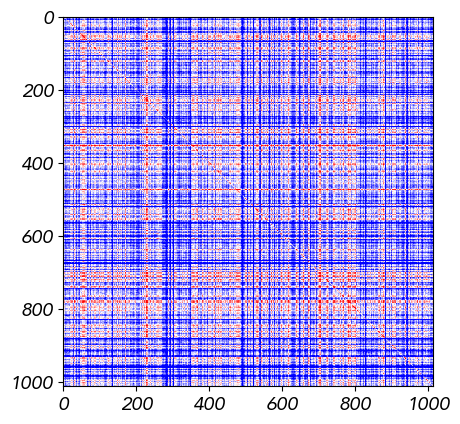

In [45]:
plt.imshow(mat,vmin =0.3,vmax=.4, cmap='bwr');

In [13]:
JS_1_62 = np.asarray(JS_1_62)
JS_2_62 = np.asarray(JS_2_62)


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.lines import Line2D


# ==========================================================
# Plot settings
# ==========================================================

markers = ['-o', '-X', '-s']

reds = cm.Reds(np.linspace(0.4, 0.9, 3))
blues = cm.Blues(np.linspace(0.4, 0.9, 3))

sample_sizes = [50, 100, 200, 300, 400, 500, 600, 700, 800, 953]
n_realizations = 200

# Dataset da usare negli istogrammi:
# 0 = 62 ROI
# 1 = 100 ROI
# 2 = 200 ROI
hist_dataset_index = 1


# ==========================================================
# Utilities
# ==========================================================

def offdiag_vector(matrix):
    """
    Restituisce tutti gli elementi fuori diagonale,
    mantenendo entrambe le direzioni i->j e j->i.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)

    return matrix[mask]


def matrices_to_features(matrices, symmetrize=True):
    """
    Trasforma un insieme di matrici in una matrice:
        subjects x features

    Se symmetrize=True:
        usa la parte simmetrica e il triangolo superiore.

    Se symmetrize=False:
        usa tutti gli elementi fuori diagonale,
        mantenendo entrambe le direzioni.
    """

    matrices = np.asarray(matrices)

    if matrices.ndim != 3:
        raise ValueError(
            "Expected matrices with shape "
            "(n_subjects, n_regions, n_regions)."
        )

    if symmetrize:

        matrices = 0.5 * (
            matrices + np.transpose(matrices, (0, 2, 1))
        )

        indices = np.triu_indices(
            matrices.shape[1],
            k=1
        )

        features = matrices[:, indices[0], indices[1]]

    else:

        mask = ~np.eye(
            matrices.shape[1],
            dtype=bool
        )

        features = matrices[:, mask]

    return features


# ==========================================================
# Identification matrix
# ==========================================================

def compute_identification_matrix(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Calcola la data-identification matrix tra sessione 1
    e sessione 2.

    Le righe rappresentano i soggetti della sessione 1.
    Le colonne rappresentano i soggetti della sessione 2.
    """

    X1 = matrices_to_features(
        matrix_1,
        symmetrize=symmetrize
    )

    X2 = matrices_to_features(
        matrix_2,
        symmetrize=symmetrize
    )

    if X1.shape[0] != X2.shape[0]:
        raise ValueError(
            "matrix_1 and matrix_2 must contain "
            "the same number of subjects."
        )

    corr = np.corrcoef(
        np.vstack([X1, X2])
    )

    n_subjects = X1.shape[0]

    identification_matrix = corr[
        :n_subjects,
        n_subjects:
    ]

    return identification_matrix


def identification_distributions(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Restituisce separatamente:

    - elementi diagonali della identification matrix;
    - elementi fuori diagonale.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    diagonal = np.diag(
        identification_matrix
    )

    offdiagonal_mask = ~np.eye(
        identification_matrix.shape[0],
        dtype=bool
    )

    offdiagonal = identification_matrix[
        offdiagonal_mask
    ]

    return identification_matrix, diagonal, offdiagonal


# ==========================================================
# Fingerprinting accuracy
# ==========================================================

def compute_accuracy(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Compute fingerprinting accuracy between two sets
    of connectivity matrices.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    predictions = identification_matrix.argmax(
        axis=1
    )

    true_subjects = np.arange(
        identification_matrix.shape[0]
    )

    accuracy = np.mean(
        predictions == true_subjects
    )

    return accuracy * 100


# ==========================================================
# Bootstrap curve
# ==========================================================

def bootstrap_curve(
    data_1,
    data_2,
    sample_sizes,
    n_realizations,
    symmetrize=True,
    random_state=None
):

    rng = np.random.default_rng(
        random_state
    )

    data_1 = np.asarray(data_1)
    data_2 = np.asarray(data_2)

    n_subjects = len(data_1)

    means = []
    errors = []

    for sample_size in sample_sizes:

        if sample_size > n_subjects:
            means.append(np.nan)
            errors.append(np.nan)
            continue

        accuracies = []

        n_iter = int(
            np.ceil(
                n_realizations / sample_size * 50
            )
        )

        # Evita che il numero di iterazioni diventi troppo basso
        n_iter = max(n_iter, 3)

        for _ in range(n_iter):

            selected = rng.choice(
                n_subjects,
                size=sample_size,
                replace=False
            )

            acc = compute_accuracy(
                data_1[selected],
                data_2[selected],
                symmetrize=symmetrize
            )

            accuracies.append(acc)

        accuracies = np.asarray(
            accuracies
        )

        means.append(
            np.mean(accuracies)
        )

        errors.append(
            np.std(
                accuracies,
                ddof=1
            ) / np.sqrt(len(accuracies))
            if len(accuracies) > 1
            else 0
        )

    return (
        np.asarray(means),
        np.asarray(errors)
    )


# ==========================================================
# Datasets
# ==========================================================

ec_data = [
    ("EC 62 ROIs",  JS_1_62,  JS_2_62),
    ("EC 100 ROIs", JS_1_100, JS_2_100),
    ("EC 200 ROIs", JS_new,    JS_new_2),
]

fc_data = [
    ("FC 62 ROIs",  fc_1_62,  fc_2_62),
    ("FC 100 ROIs", fc_1_100, fc_2_100),
    ("FC 200 ROIs", fc_1_200, fc_2_200),
]


# ==========================================================
# Compute bootstrap curves
# ==========================================================

m_ecc = []
err_ecc = []

for i, (label, data_1, data_2) in enumerate(ec_data):

    print(label, data_1.shape)

    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations,
        symmetrize=False,
        random_state=100 + i
    )

    m_ecc.append(means)
    err_ecc.append(errors)


m_fcc = []
err_fcc = []

for i, (label, data_1, data_2) in enumerate(fc_data):

    print(label, data_1.shape)

    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations,
        symmetrize=True,
        random_state=200 + i
    )

    m_fcc.append(means)
    err_fcc.append(errors)


m_ecc = np.asarray(m_ecc)
err_ecc = np.asarray(err_ecc)

m_fcc = np.asarray(m_fcc)
err_fcc = np.asarray(err_fcc)


# ==========================================================
# Identification distributions for selected parcellation
# ==========================================================
hist_dataset_index = 1

ec_hist_label, ec_hist_1, ec_hist_2 = ec_data[
    hist_dataset_index
]

fc_hist_label, fc_hist_1, fc_hist_2 = fc_data[
    hist_dataset_index
]


ec_identification, ec_diagonal, ec_offdiagonal = (
    identification_distributions(
        ec_hist_1,
        ec_hist_2,
        symmetrize=False
    )
)


fc_identification, fc_diagonal, fc_offdiagonal = (
    identification_distributions(
        fc_hist_1,
        fc_hist_2,
        symmetrize=True
    )
)



EC 62 ROIs (1013, 62, 62)
EC 100 ROIs (1013, 100, 100)
EC 200 ROIs (953, 200, 200)
FC 62 ROIs (1013, 62, 62)
FC 100 ROIs (1013, 100, 100)
FC 200 ROIs (1013, 200, 200)


EC 100 ROIs: within-subject mean = 0.728, between-subject mean = 0.576
FC 100 ROIs: within-subject mean = 0.705, between-subject mean = 0.520


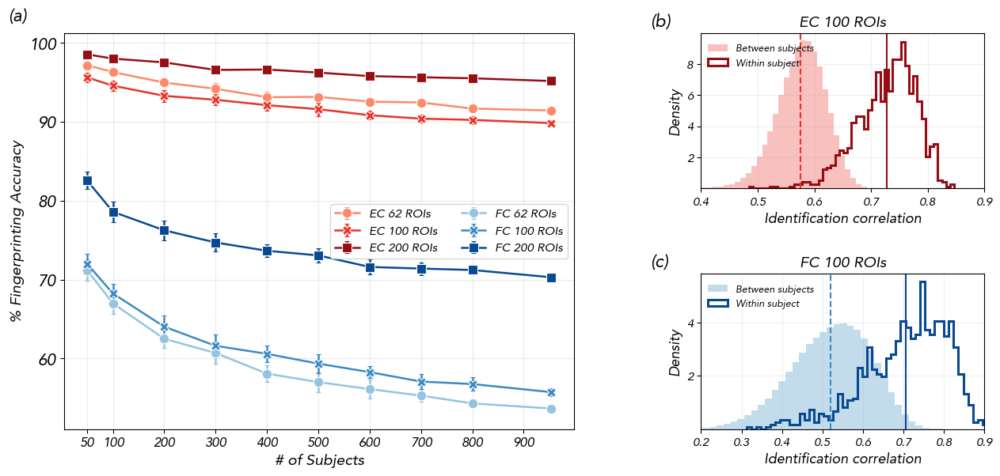

In [33]:
# ==========================================================
hist_dataset_index = 1

ec_hist_label, ec_hist_1, ec_hist_2 = ec_data[
    hist_dataset_index
]

fc_hist_label, fc_hist_1, fc_hist_2 = fc_data[
    hist_dataset_index
]


ec_identification, ec_diagonal, ec_offdiagonal = (
    identification_distributions(
        ec_hist_1,
        ec_hist_2,
        symmetrize=False
    )
)


fc_identification, fc_diagonal, fc_offdiagonal = (
    identification_distributions(
        fc_hist_1,
        fc_hist_2,
        symmetrize=True
    )
)


# ==========================================================
# Figure layout
# ==========================================================

fig = plt.figure(
    figsize=(15, 6.5)
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[1.8, 1],
    height_ratios=[1, 1],
    wspace=0.32,
    hspace=0.55
)

ax_curve = fig.add_subplot(
    gs[:, 0]
)

ax_ec_hist = fig.add_subplot(
    gs[0, 1]
)

ax_fc_hist = fig.add_subplot(
    gs[1, 1]
)


# ==========================================================
# Panel A: fingerprinting accuracy
# ==========================================================

for i, (label, _, _) in enumerate(ec_data):

    ax_curve.errorbar(
        sample_sizes,
        m_ecc[i],
        yerr=3 * err_ecc[i],
        fmt=markers[i],
        color=reds[i],
        ecolor=reds[i],
        markeredgecolor='white',
        markeredgewidth=0.8,
        capsize=2,
        markersize=9,
        linewidth=1.8,
        label=label
    )


for i, (label, _, _) in enumerate(fc_data):

    ax_curve.errorbar(
        sample_sizes,
        m_fcc[i],
        yerr=3 * err_fcc[i],
        fmt=markers[i],
        color=blues[i],
        ecolor=blues[i],
        markeredgecolor='white',
        markeredgewidth=0.8,
        capsize=2,
        markersize=9,
        linewidth=1.8,
        label=label
    )


ax_curve.set_xlabel(
    '# of Subjects',
   # fontsize=16
)

ax_curve.set_ylabel(
    '% Fingerprinting Accuracy',
   # fontsize=16
)

ax_curve.set_xticks(
    sample_sizes
)

ax_curve.tick_params(
    axis='both',
   labelsize=15
)

ax_curve.grid(
    True,
    alpha=0.25
)

ax_curve.legend(
    fontsize=11,
    frameon=True,
    ncol=2,
    loc='best'
)

ax_curve.text(
    -0.11,
    1.03,
    '(a)',
    transform=ax_curve.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Shared histogram bins
# ==========================================================

all_values = np.concatenate([
    ec_diagonal,
    ec_offdiagonal,
    fc_diagonal,
    fc_offdiagonal
])

hist_min = np.nanpercentile(
    all_values,
    0.1
)

hist_max = np.nanpercentile(
    all_values,
    99.9
)

bins = np.linspace(
    hist_min,
    hist_max,
    45
)


# ==========================================================
# Panel B: EC identification distributions
# ==========================================================

ax_ec_hist.hist(
    ec_offdiagonal,
    bins=50,
    density=True,
    histtype='stepfilled',
    alpha=0.30,
    color=reds[1],
    label='Between subjects'
)

ax_ec_hist.hist(
    ec_diagonal,
    bins=50,
    density=True,
    histtype='step',
    linewidth=2.2,
    color=reds[2],
    label='Within subject'
)

ax_ec_hist.axvline(
    np.mean(ec_offdiagonal),
    color=reds[1],
    linestyle='--',
    linewidth=1.5
)

ax_ec_hist.axvline(
    np.mean(ec_diagonal),
    color=reds[2],
    linestyle='-',
    linewidth=1.5
)

ax_ec_hist.set_title(
    ec_hist_label,
    fontsize=14
)

ax_ec_hist.set_ylabel(
    'Density',
    fontsize=13
)

ax_ec_hist.set_xlabel(
    'Identification correlation',
    fontsize=13
)

ax_ec_hist.legend(
    loc = (0.01,0.75),
    fontsize=9,
    frameon=False
)

ax_ec_hist.grid(
    True,
    alpha=0.20
)

ax_ec_hist.text(
    -0.18,
    1.04,
    '(b)',
    transform=ax_ec_hist.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Panel C: FC identification distributions
# ==========================================================

ax_fc_hist.hist(
    fc_offdiagonal,
    bins=50,
    density=True,
    histtype='stepfilled',
    alpha=0.30,
    color=blues[1],
    label='Between subjects'
)

ax_fc_hist.hist(
    fc_diagonal,
    bins=50,
    density=True,
    histtype='step',
    linewidth=2.2,
    color=blues[2],
    label='Within subject'
)

ax_fc_hist.axvline(
    np.mean(fc_offdiagonal),
    color=blues[1],
    linestyle='--',
    linewidth=1.5
)

ax_fc_hist.axvline(
    np.mean(fc_diagonal),
    color=blues[2],
    linestyle='-',
    linewidth=1.5
)

ax_fc_hist.set_title(
    fc_hist_label,
    fontsize=14
)

ax_fc_hist.set_ylabel(
    'Density',
    fontsize=13
)

ax_fc_hist.set_xlabel(
    'Identification correlation',
    fontsize=13
)

ax_fc_hist.legend(
    loc = (0.01,0.75),
    fontsize=9,
    frameon=False
)

ax_fc_hist.grid(
    True,
    alpha=0.20
)

ax_fc_hist.text(
    -0.18,
    1.04,
    '(c)',
    transform=ax_fc_hist.transAxes,
    fontsize=16,
    fontweight='bold'
)


# Same horizontal range for EC and FC histograms
#ax_ec_hist.set_xlim(
  #  hist_min,
 #   hist_max
#)

ax_ec_hist.set_xticks([0.3,0.4,0.5,0.6,0.7,0.8,0.9])#, fontsize = 11
ax_ec_hist.set_xticklabels([0.3,.4,0.5,0.6,0.7,0.8,0.9], fontsize = 11)
ax_ec_hist.set_xlim(0.4,.9)
ax_fc_hist.set_xlim(0.2,.9)
ax_ec_hist.set_yticks( [2,4,6,8],)
ax_fc_hist.set_yticks( [2,4],)

ax_ec_hist.set_yticklabels([2,4,6,8], fontsize = 11)
ax_fc_hist.set_yticklabels( [2,4],fontsize = 11)


ax_fc_hist.set_xticks([0.2,0.3,.4,0.5,0.6,0.7,0.8,0.9])#, fontsize = 11
ax_fc_hist.set_xticklabels([0.2,.3,.4,0.5,0.6,0.7,0.8,0.9],fontsize = 11)



# ==========================================================
# Optional summary statistics
# ==========================================================

print(
    f"{ec_hist_label}: "
    f"within-subject mean = {np.mean(ec_diagonal):.3f}, "
    f"between-subject mean = {np.mean(ec_offdiagonal):.3f}"
)

print(
    f"{fc_hist_label}: "
    f"within-subject mean = {np.mean(fc_diagonal):.3f}, "
    f"between-subject mean = {np.mean(fc_offdiagonal):.3f}"
)


# ==========================================================
# Final formatting
# ==========================================================
ax_curve.set_xticks([50,100,200,300,400,500,600,700,800,900],)
ax_curve.set_xticklabels([50,100,200,300,400,500,600,700,800,900], fontsize =12)
"""
plt.savefig(
    '../Figures/Fingerprinting_with_identification_distributions.jpg',
    dpi=300,
    bbox_inches='tight')
"""
plt.show()

## EC with data not filtered

EC 62 ROIs (1013, 62, 62)
EC 62 ROIs: within-subject mean = 0.762, between-subject mean = 0.579
FC 100 ROIs: within-subject mean = 0.705, between-subject mean = 0.520


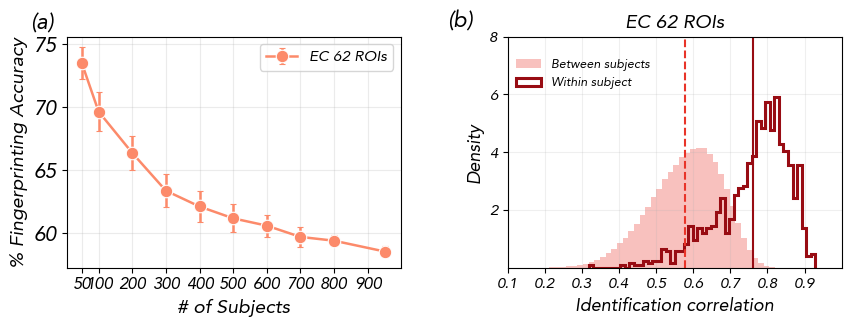

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.lines import Line2D


# ==========================================================
# Plot settings
# ==========================================================

markers = ['-o', '-X', '-s']

reds = cm.Reds(np.linspace(0.4, 0.9, 3))
blues = cm.Blues(np.linspace(0.4, 0.9, 3))

sample_sizes = [50, 100, 200, 300, 400, 500, 600, 700, 800, 953]
n_realizations = 200

# Dataset da usare negli istogrammi:
# 0 = 62 ROI#
# 1 = 100 ROI
# 2 = 200 ROI
#hist_dataset_index = 1


# ==========================================================
# Utilities
# ==========================================================

def offdiag_vector(matrix):
    """
    Restituisce tutti gli elementi fuori diagonale,
    mantenendo entrambe le direzioni i->j e j->i.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)

    return matrix[mask]


def matrices_to_features(matrices, symmetrize=True):
    """
    Trasforma un insieme di matrici in una matrice:
        subjects x features

    Se symmetrize=True:
        usa la parte simmetrica e il triangolo superiore.

    Se symmetrize=False:
        usa tutti gli elementi fuori diagonale,
        mantenendo entrambe le direzioni.
    """

    matrices = np.asarray(matrices)

    if matrices.ndim != 3:
        raise ValueError(
            "Expected matrices with shape "
            "(n_subjects, n_regions, n_regions)."
        )

    if symmetrize:

        matrices = 0.5 * (
            matrices + np.transpose(matrices, (0, 2, 1))
        )

        indices = np.triu_indices(
            matrices.shape[1],
            k=1
        )

        features = matrices[:, indices[0], indices[1]]

    else:

        mask = ~np.eye(
            matrices.shape[1],
            dtype=bool
        )

        features = matrices[:, mask]

    return features


# ==========================================================
# Identification matrix
# ==========================================================

def compute_identification_matrix(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Calcola la data-identification matrix tra sessione 1
    e sessione 2.

    Le righe rappresentano i soggetti della sessione 1.
    Le colonne rappresentano i soggetti della sessione 2.
    """

    X1 = matrices_to_features(
        matrix_1,
        symmetrize=symmetrize
    )

    X2 = matrices_to_features(
        matrix_2,
        symmetrize=symmetrize
    )

    if X1.shape[0] != X2.shape[0]:
        raise ValueError(
            "matrix_1 and matrix_2 must contain "
            "the same number of subjects."
        )

    corr = np.corrcoef(
        np.vstack([X1, X2])
    )

    n_subjects = X1.shape[0]

    identification_matrix = corr[
        :n_subjects,
        n_subjects:
    ]

    return identification_matrix


def identification_distributions(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Restituisce separatamente:

    - elementi diagonali della identification matrix;
    - elementi fuori diagonale.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    diagonal = np.diag(
        identification_matrix
    )

    offdiagonal_mask = ~np.eye(
        identification_matrix.shape[0],
        dtype=bool
    )

    offdiagonal = identification_matrix[
        offdiagonal_mask
    ]

    return identification_matrix, diagonal, offdiagonal


# ==========================================================
# Fingerprinting accuracy
# ==========================================================

def compute_accuracy(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Compute fingerprinting accuracy between two sets
    of connectivity matrices.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    predictions = identification_matrix.argmax(
        axis=1
    )

    true_subjects = np.arange(
        identification_matrix.shape[0]
    )

    accuracy = np.mean(
        predictions == true_subjects
    )

    return accuracy * 100


# ==========================================================
# Bootstrap curve
# ==========================================================

def bootstrap_curve(
    data_1,
    data_2,
    sample_sizes,
    n_realizations,
    symmetrize=True,
    random_state=None
):

    rng = np.random.default_rng(
        random_state
    )

    data_1 = np.asarray(data_1)
    data_2 = np.asarray(data_2)

    n_subjects = len(data_1)

    means = []
    errors = []

    for sample_size in sample_sizes:

        if sample_size > n_subjects:
            means.append(np.nan)
            errors.append(np.nan)
            continue

        accuracies = []

        n_iter = int(
            np.ceil(
                n_realizations / sample_size * 50
            )
        )

        # Evita che il numero di iterazioni diventi troppo basso
        n_iter = max(n_iter, 3)

        for _ in range(n_iter):

            selected = rng.choice(
                n_subjects,
                size=sample_size,
                replace=False
            )

            acc = compute_accuracy(
                data_1[selected],
                data_2[selected],
                symmetrize=symmetrize
            )

            accuracies.append(acc)

        accuracies = np.asarray(
            accuracies
        )

        means.append(
            np.mean(accuracies)
        )

        errors.append(
            np.std(
                accuracies,
                ddof=1
            ) / np.sqrt(len(accuracies))
            if len(accuracies) > 1
            else 0
        )

    return (
        np.asarray(means),
        np.asarray(errors)
    )


# ==========================================================
# Datasets
# ==========================================================

ec_data = [
    ("EC 62 ROIs",  np.asarray(fc_1_62),   np.asarray(fc_2_62)),
]



# ==========================================================
# Compute bootstrap curves
# ==========================================================
val =True
m_ecc = []
err_ecc = []

for i, (label, data_1, data_2) in enumerate(ec_data):

    print(label, data_1.shape)

    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations,
        symmetrize=val,
        random_state=100 + i
    )

    m_ecc.append(means)
    err_ecc.append(errors)


m_ecc = np.asarray(m_ecc)
err_ecc = np.asarray(err_ecc)

#m_fcc = np.asarray(m_fcc)
#err_fcc = np.asarray(err_fcc)


# ==========================================================
# Identification distributions for selected parcellation
# =========================================================
hist_dataset_index = 0

ec_hist_label, ec_hist_1, ec_hist_2 = ec_data[
    hist_dataset_index
]



ec_identification, ec_diagonal, ec_offdiagonal = (
    identification_distributions(
        ec_hist_1,
        ec_hist_2,
        symmetrize=val
    )
)






# ==========================================================
# Figure layout
# ==========================================================

fig = plt.figure(
    figsize=(10, 3)
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[1, 1],
    height_ratios=[.5, .5],
    wspace=0.32,
    hspace=0.55
)

ax_curve = fig.add_subplot(
    gs[:, 0]
)

ax_ec_hist = fig.add_subplot(
    gs[:, 1]
)



# ==========================================================
# Panel A: fingerprinting accuracy
# ==========================================================

for i, (label, _, _) in enumerate(ec_data):

    ax_curve.errorbar(
        sample_sizes,
        m_ecc[i],
        yerr=3 * err_ecc[i],
        fmt=markers[i],
        color=reds[i],
        ecolor=reds[i],
        markeredgecolor='white',
        markeredgewidth=0.8,
        capsize=2,
        markersize=9,
        linewidth=1.8,
        label=label
    )





ax_curve.set_xlabel(
    '# of Subjects',
   # fontsize=16
)

ax_curve.set_ylabel(
    '% Fingerprinting Accuracy',
   # fontsize=16
)

ax_curve.set_xticks(
    sample_sizes
)

ax_curve.tick_params(
    axis='both',
   labelsize=15
)

ax_curve.grid(
    True,
    alpha=0.25
)

ax_curve.legend(
    fontsize=11,
    frameon=True,
    ncol=2,
    loc='best'
)

ax_curve.text(
    -0.11,
    1.03,
    '(a)',
    transform=ax_curve.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Shared histogram bins
# ==========================================================

all_values = np.concatenate([
    ec_diagonal,
    ec_offdiagonal,
   # fc_diagonal,
   # fc_offdiagonal
])

hist_min = np.nanpercentile(
    all_values,
    0.1
)

hist_max = np.nanpercentile(
    all_values,
    99.9
)

bins = np.linspace(
    hist_min,
    hist_max,
    45
)


# ==========================================================
# Panel B: EC identification distributions
# ==========================================================

ax_ec_hist.hist(
    ec_offdiagonal,
    bins=50,
    density=True,
    histtype='stepfilled',
    alpha=0.30,
    color=reds[1],
    label='Between subjects'
)

ax_ec_hist.hist(
    ec_diagonal,
    bins=50,
    density=True,
    histtype='step',
    linewidth=2.2,
    color=reds[2],
    label='Within subject'
)

ax_ec_hist.axvline(
    np.mean(ec_offdiagonal),
    color=reds[1],
    linestyle='--',
    linewidth=1.5
)

ax_ec_hist.axvline(
    np.mean(ec_diagonal),
    color=reds[2],
    linestyle='-',
    linewidth=1.5
)

ax_ec_hist.set_title(
    ec_hist_label,
    fontsize=14
)

ax_ec_hist.set_ylabel(
    'Density',
    fontsize=13
)

ax_ec_hist.set_xlabel(
    'Identification correlation',
    fontsize=13
)

ax_ec_hist.legend(
    loc = (0.01,0.75),
    fontsize=9,
    frameon=False
)

ax_ec_hist.grid(
    True,
    alpha=0.20
)

ax_ec_hist.text(
    -0.18,
    1.04,
    '(b)',
    transform=ax_ec_hist.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Panel C: FC identification distributions
# ==========================================================


# Same horizontal range for EC and FC histograms
#ax_ec_hist.set_xlim(
  #  hist_min,
 #   hist_max
#)

ax_ec_hist.set_xticks([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])#, fontsize = 11
ax_ec_hist.set_xticklabels([0.1,0.2,0.3,.4,0.5,0.6,0.7,0.8,0.9], fontsize = 11)
ax_ec_hist.set_xlim(0.1,1)
ax_ec_hist.set_yticks( [2,4,6,8],)

ax_ec_hist.set_yticklabels([2,4,6,8], fontsize = 11)


# ==========================================================
# Optional summary statistics
# ==========================================================

print(
    f"{ec_hist_label}: "
    f"within-subject mean = {np.mean(ec_diagonal):.3f}, "
    f"between-subject mean = {np.mean(ec_offdiagonal):.3f}"
)

print(
    f"{fc_hist_label}: "
    f"within-subject mean = {np.mean(fc_diagonal):.3f}, "
    f"between-subject mean = {np.mean(fc_offdiagonal):.3f}"
)


# ==========================================================
# Final formatting
# ==========================================================
ax_curve.set_xticks([50,100,200,300,400,500,600,700,800,900],)
ax_curve.set_xticklabels([50,100,200,300,400,500,600,700,800,900], fontsize =12)
#plt.savefig(
#    '../Figures/Fingerprinting_not_filtered.jpg',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

EC 62 ROIs (1013, 62, 62)
EC 62 ROIs: within-subject mean = 0.713, between-subject mean = 0.524
FC 100 ROIs: within-subject mean = 0.705, between-subject mean = 0.520


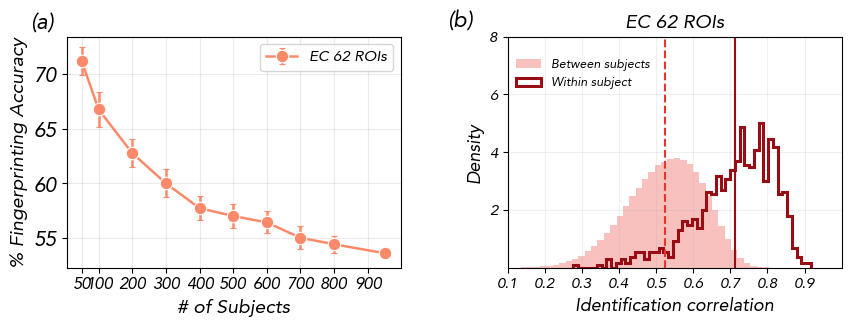

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.lines import Line2D


# ==========================================================
# Plot settings
# ==========================================================

markers = ['-o', '-X', '-s']

reds = cm.Reds(np.linspace(0.4, 0.9, 3))
blues = cm.Blues(np.linspace(0.4, 0.9, 3))

sample_sizes = [50, 100, 200, 300, 400, 500, 600, 700, 800, 953]
n_realizations = 200

# Dataset da usare negli istogrammi:
# 0 = 62 ROI#
# 1 = 100 ROI
# 2 = 200 ROI
#hist_dataset_index = 1


# ==========================================================
# Utilities
# ==========================================================

def offdiag_vector(matrix):
    """
    Restituisce tutti gli elementi fuori diagonale,
    mantenendo entrambe le direzioni i->j e j->i.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)

    return matrix[mask]


def matrices_to_features(matrices, symmetrize=True):
    """
    Trasforma un insieme di matrici in una matrice:
        subjects x features

    Se symmetrize=True:
        usa la parte simmetrica e il triangolo superiore.

    Se symmetrize=False:
        usa tutti gli elementi fuori diagonale,
        mantenendo entrambe le direzioni.
    """

    matrices = np.asarray(matrices)

    if matrices.ndim != 3:
        raise ValueError(
            "Expected matrices with shape "
            "(n_subjects, n_regions, n_regions)."
        )

    if symmetrize:

        matrices = 0.5 * (
            matrices + np.transpose(matrices, (0, 2, 1))
        )

        indices = np.triu_indices(
            matrices.shape[1],
            k=1
        )

        features = matrices[:, indices[0], indices[1]]

    else:

        mask = ~np.eye(
            matrices.shape[1],
            dtype=bool
        )

        features = matrices[:, mask]

    return features


# ==========================================================
# Identification matrix
# ==========================================================

def compute_identification_matrix(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Calcola la data-identification matrix tra sessione 1
    e sessione 2.

    Le righe rappresentano i soggetti della sessione 1.
    Le colonne rappresentano i soggetti della sessione 2.
    """

    X1 = matrices_to_features(
        matrix_1,
        symmetrize=symmetrize
    )

    X2 = matrices_to_features(
        matrix_2,
        symmetrize=symmetrize
    )

    if X1.shape[0] != X2.shape[0]:
        raise ValueError(
            "matrix_1 and matrix_2 must contain "
            "the same number of subjects."
        )

    corr = np.corrcoef(
        np.vstack([X1, X2])
    )

    n_subjects = X1.shape[0]

    identification_matrix = corr[
        :n_subjects,
        n_subjects:
    ]

    return identification_matrix


def identification_distributions(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Restituisce separatamente:

    - elementi diagonali della identification matrix;
    - elementi fuori diagonale.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    diagonal = np.diag(
        identification_matrix
    )

    offdiagonal_mask = ~np.eye(
        identification_matrix.shape[0],
        dtype=bool
    )

    offdiagonal = identification_matrix[
        offdiagonal_mask
    ]

    return identification_matrix, diagonal, offdiagonal


# ==========================================================
# Fingerprinting accuracy
# ==========================================================

def compute_accuracy(
    matrix_1,
    matrix_2,
    symmetrize=True
):
    """
    Compute fingerprinting accuracy between two sets
    of connectivity matrices.
    """

    identification_matrix = compute_identification_matrix(
        matrix_1,
        matrix_2,
        symmetrize=symmetrize
    )

    predictions = identification_matrix.argmax(
        axis=1
    )

    true_subjects = np.arange(
        identification_matrix.shape[0]
    )

    accuracy = np.mean(
        predictions == true_subjects
    )

    return accuracy * 100


# ==========================================================
# Bootstrap curve
# ==========================================================

def bootstrap_curve(
    data_1,
    data_2,
    sample_sizes,
    n_realizations,
    symmetrize=True,
    random_state=None
):

    rng = np.random.default_rng(
        random_state
    )

    data_1 = np.asarray(data_1)
    data_2 = np.asarray(data_2)

    n_subjects = len(data_1)

    means = []
    errors = []

    for sample_size in sample_sizes:

        if sample_size > n_subjects:
            means.append(np.nan)
            errors.append(np.nan)
            continue

        accuracies = []

        n_iter = int(
            np.ceil(
                n_realizations / sample_size * 50
            )
        )

        # Evita che il numero di iterazioni diventi troppo basso
        n_iter = max(n_iter, 3)

        for _ in range(n_iter):

            selected = rng.choice(
                n_subjects,
                size=sample_size,
                replace=False
            )

            acc = compute_accuracy(
                data_1[selected],
                data_2[selected],
                symmetrize=symmetrize
            )

            accuracies.append(acc)

        accuracies = np.asarray(
            accuracies
        )

        means.append(
            np.mean(accuracies)
        )

        errors.append(
            np.std(
                accuracies,
                ddof=1
            ) / np.sqrt(len(accuracies))
            if len(accuracies) > 1
            else 0
        )

    return (
        np.asarray(means),
        np.asarray(errors)
    )


# ==========================================================
# Datasets
# ==========================================================

ec_data = [
    ("EC 62 ROIs",  np.asarray(fc_1_62),   np.asarray(fc_2_62)),
]



# ==========================================================
# Compute bootstrap curves
# ==========================================================
val =True
m_ecc = []
err_ecc = []

for i, (label, data_1, data_2) in enumerate(ec_data):

    print(label, data_1.shape)

    means, errors = bootstrap_curve(
        data_1,
        data_2,
        sample_sizes,
        n_realizations,
        symmetrize=val,
        random_state=100 + i
    )

    m_ecc.append(means)
    err_ecc.append(errors)


m_ecc = np.asarray(m_ecc)
err_ecc = np.asarray(err_ecc)

#m_fcc = np.asarray(m_fcc)
#err_fcc = np.asarray(err_fcc)


# ==========================================================
# Identification distributions for selected parcellation
# =========================================================
hist_dataset_index = 0

ec_hist_label, ec_hist_1, ec_hist_2 = ec_data[
    hist_dataset_index
]



ec_identification, ec_diagonal, ec_offdiagonal = (
    identification_distributions(
        ec_hist_1,
        ec_hist_2,
        symmetrize=val
    )
)






# ==========================================================
# Figure layout
# ==========================================================

fig = plt.figure(
    figsize=(10, 3)
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[1, 1],
    height_ratios=[.5, .5],
    wspace=0.32,
    hspace=0.55
)

ax_curve = fig.add_subplot(
    gs[:, 0]
)

ax_ec_hist = fig.add_subplot(
    gs[:, 1]
)



# ==========================================================
# Panel A: fingerprinting accuracy
# ==========================================================

for i, (label, _, _) in enumerate(ec_data):

    ax_curve.errorbar(
        sample_sizes,
        m_ecc[i],
        yerr=3 * err_ecc[i],
        fmt=markers[i],
        color=reds[i],
        ecolor=reds[i],
        markeredgecolor='white',
        markeredgewidth=0.8,
        capsize=2,
        markersize=9,
        linewidth=1.8,
        label=label
    )





ax_curve.set_xlabel(
    '# of Subjects',
   # fontsize=16
)

ax_curve.set_ylabel(
    '% Fingerprinting Accuracy',
   # fontsize=16
)

ax_curve.set_xticks(
    sample_sizes
)

ax_curve.tick_params(
    axis='both',
   labelsize=15
)

ax_curve.grid(
    True,
    alpha=0.25
)

ax_curve.legend(
    fontsize=11,
    frameon=True,
    ncol=2,
    loc='best'
)

ax_curve.text(
    -0.11,
    1.03,
    '(a)',
    transform=ax_curve.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Shared histogram bins
# ==========================================================

all_values = np.concatenate([
    ec_diagonal,
    ec_offdiagonal,
   # fc_diagonal,
   # fc_offdiagonal
])

hist_min = np.nanpercentile(
    all_values,
    0.1
)

hist_max = np.nanpercentile(
    all_values,
    99.9
)

bins = np.linspace(
    hist_min,
    hist_max,
    45
)


# ==========================================================
# Panel B: EC identification distributions
# ==========================================================

ax_ec_hist.hist(
    ec_offdiagonal,
    bins=50,
    density=True,
    histtype='stepfilled',
    alpha=0.30,
    color=reds[1],
    label='Between subjects'
)

ax_ec_hist.hist(
    ec_diagonal,
    bins=50,
    density=True,
    histtype='step',
    linewidth=2.2,
    color=reds[2],
    label='Within subject'
)

ax_ec_hist.axvline(
    np.mean(ec_offdiagonal),
    color=reds[1],
    linestyle='--',
    linewidth=1.5
)

ax_ec_hist.axvline(
    np.mean(ec_diagonal),
    color=reds[2],
    linestyle='-',
    linewidth=1.5
)

ax_ec_hist.set_title(
    ec_hist_label,
    fontsize=14
)

ax_ec_hist.set_ylabel(
    'Density',
    fontsize=13
)

ax_ec_hist.set_xlabel(
    'Identification correlation',
    fontsize=13
)

ax_ec_hist.legend(
    loc = (0.01,0.75),
    fontsize=9,
    frameon=False
)

ax_ec_hist.grid(
    True,
    alpha=0.20
)

ax_ec_hist.text(
    -0.18,
    1.04,
    '(b)',
    transform=ax_ec_hist.transAxes,
    fontsize=16,
    fontweight='bold'
)


# ==========================================================
# Panel C: FC identification distributions
# ==========================================================


# Same horizontal range for EC and FC histograms
#ax_ec_hist.set_xlim(
  #  hist_min,
 #   hist_max
#)

ax_ec_hist.set_xticks([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])#, fontsize = 11
ax_ec_hist.set_xticklabels([0.1,0.2,0.3,.4,0.5,0.6,0.7,0.8,0.9], fontsize = 11)
ax_ec_hist.set_xlim(0.1,1)
ax_ec_hist.set_yticks( [2,4,6,8],)

ax_ec_hist.set_yticklabels([2,4,6,8], fontsize = 11)


# ==========================================================
# Optional summary statistics
# ==========================================================

print(
    f"{ec_hist_label}: "
    f"within-subject mean = {np.mean(ec_diagonal):.3f}, "
    f"between-subject mean = {np.mean(ec_offdiagonal):.3f}"
)

print(
    f"{fc_hist_label}: "
    f"within-subject mean = {np.mean(fc_diagonal):.3f}, "
    f"between-subject mean = {np.mean(fc_offdiagonal):.3f}"
)


# ==========================================================
# Final formatting
# ==========================================================
ax_curve.set_xticks([50,100,200,300,400,500,600,700,800,900],)
ax_curve.set_xticklabels([50,100,200,300,400,500,600,700,800,900], fontsize =12)
#plt.savefig(
#    '../Figures/Fingerprinting_not_filtered.jpg',
#    dpi=300,
#    bbox_inches='tight')
plt.show()
.762, between-subject mean = 0.579

In [50]:
ec_identification.shape

(1013, 1013)

### plot

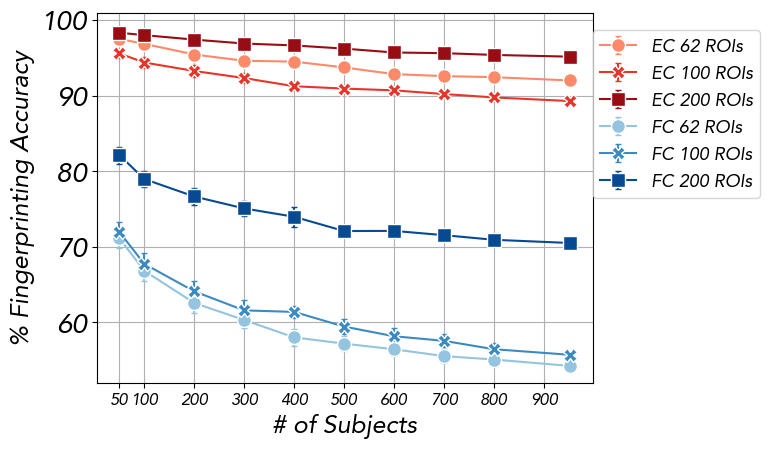

In [34]:
for i, (label, data_1, data_2) in enumerate(ec_data):


    plt.errorbar(
        sample_sizes,
        m_ec[i],
        3*err_ec[i],
        fmt=markers[i],
        color=reds[i],
        ecolor=reds[i],
        markeredgecolor='white',
        capsize=2,
        markersize=10,
        label=label
    )


# ==========================================================
# FC plots
# ==========================================================

fc_indices = np.triu_indices(fc_1_62[0].shape[0], 1)

for i, (label, data_1, data_2) in enumerate(fc_data):

    plt.errorbar(
        sample_sizes,
        m_fc[i],
        3*err_fc[i],
        fmt=markers[i],
        color=blues[i],
        ecolor=blues[i],
        markeredgecolor='white',
        capsize=2,
        markersize=10,
        label=label
    )

# ==========================================================
# Final plot formatting
# ==========================================================

plt.xlabel('# of Subjects', fontsize = 18)
plt.ylabel('% Fingerprinting Accuracy',fontsize = 18)

plt.legend(fontsize=13, loc=(1, 0.5))

# plt.savefig(
#     'Figures/Fingerprinting.jpg',
#     dpi=300,
#     bbox_inches='tight'
# )
plt.xticks([50,100,200,300,400,500,600,700,800,900], fontsize =12)
plt.grid(True)
plt.show()


In [67]:
np.asarray(m_fc).shape

(3, 10)

In [68]:
JS_1_100 = np.load('numpy files/EC_matrix_HCP1_100.npy')[:,:100,:100]
JS_2_100 = np.load('numpy files/EC_matrix_HCP2_100.npy')[:,:100,:100]
print(JS_1_100.shape)

JS_1_100_ = np.load('numpy files/JS_1_100_new.npy')
JS_2_100_ = np.load('numpy files/JS_2_100_new.npy')
print(JS_1_100_.shape)


(1013, 100, 100)
(1013, 100, 100)


True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


/tmp/ipykernel_35726/1940063313.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax = plt.subplots(1,2)


True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


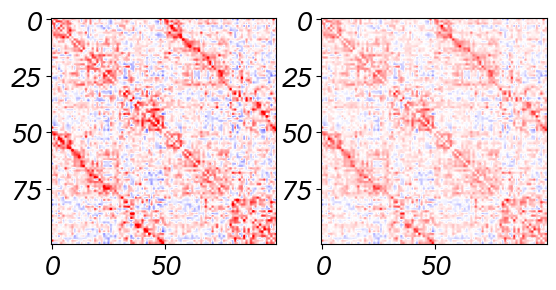

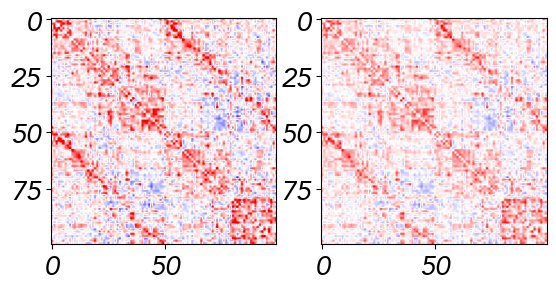

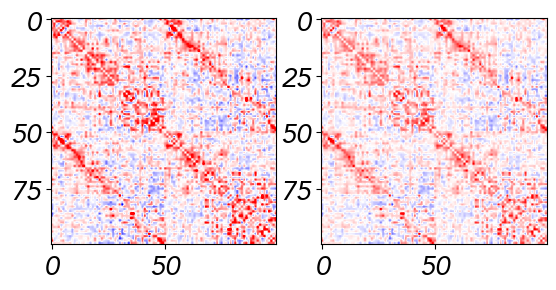

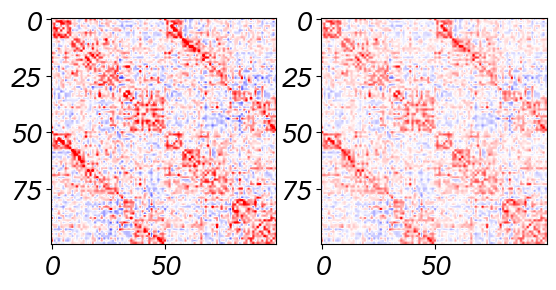

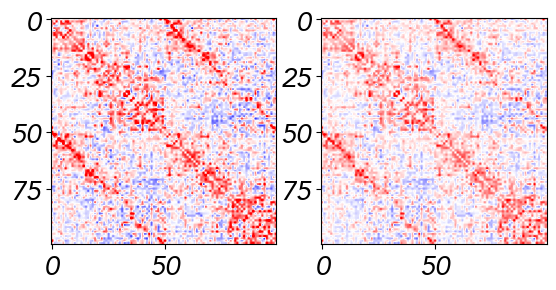

...

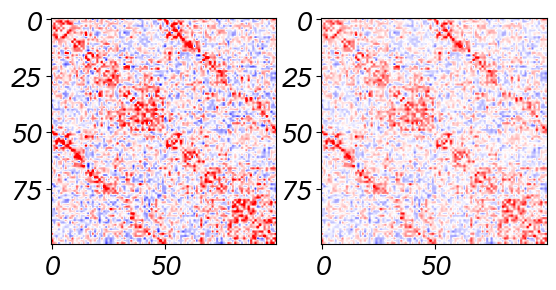

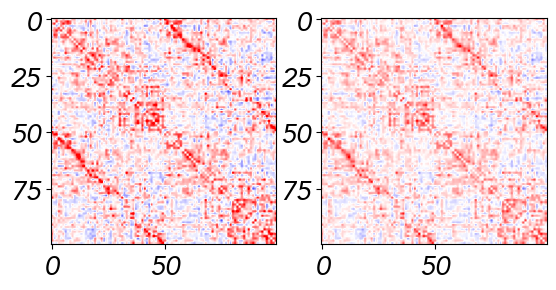

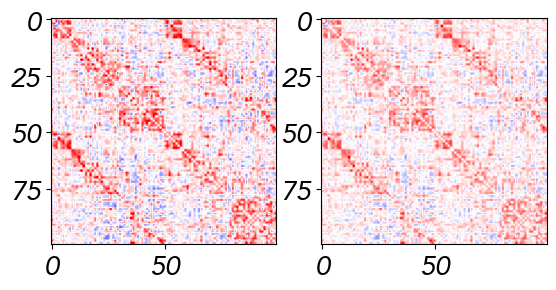

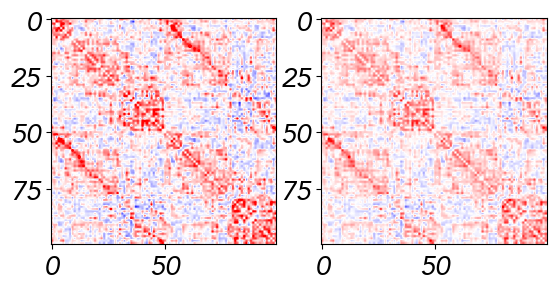

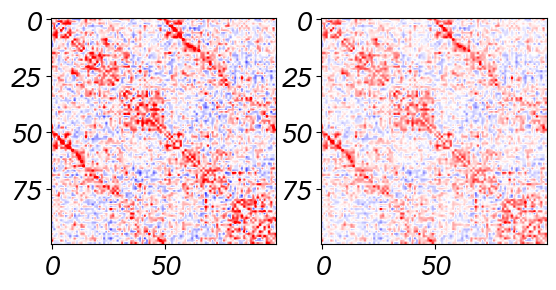

In [79]:

for i in np.arange(0,1013,20):
    fig,ax = plt.subplots(1,2)
    ax[0].imshow(dediag(JS_2_100[i]), vmin=-.1, vmax=.1,cmap='bwr')
    ax[1].imshow(dediag(JS_2_100_[i]), vmin=-.1, vmax=.1, cmap='bwr')
    
    print(np.corrcoef(dediag(JS_2_100[i]).flatten(),dediag(JS_2_100_[i]).flatten())[0,1]>0.9)

In [88]:
x=np.arange(0,1,0.001)
np.corrcoef(np.sin(x*np.pi*2*10),np.sin(x*np.pi*2*10)*5 +3)

array([[1., 1.],
       [1., 1.]])

In [656]:
np.save('numpy files/EC_matrix_HCP2_200_converged.npy', JS_new_2)
np.save('numpy files/EC_matrix_HCP1_200_converged.npy', JS_new)

In [390]:
plt.rcParams['font.size'] = 15

In [352]:
np.asarray(fc_1).shape

(1013, 212, 212)